# Pneumonia Classification with a Vision Transformer (ViT)

This notebook evaluates a pretrained Hugging Face Vision Transformer on chest X-ray images, then compares fine-tuning and inference-time modifications.

> **Scope:** This is an educational machine-learning experiment, not a clinically validated diagnostic system. Do not use its predictions for patient care.

## Project overview

The notebook compares the downloaded reference checkpoint with fine-tuned variants and inference-time strategies. The reference checkpoint was trained before this notebook; it is **not a model trained from scratch here**.

| Experiment | Configuration | Purpose |
|---|---|---|
| A | Reference ViT, raw images | Baseline evaluation |
| A2 | Reference ViT, CLAHE images | Test CLAHE at inference time |
| B | Fine-tuning with class-weighted loss | Adapt the reference checkpoint to our training split |
| B2 | Fine-tuning without class weights | Ablation for the class-weighting choice |
| C | Fine-tuning with class weights and CLAHE | Evaluate the combined modification |
| D | Reference ViT with test-time augmentation (TTA) | Average predictions across four views |
| E | Reference ViT with raw/CLAHE fusion | Average predictions from two preprocessing views |
| F | Reference ViT with fusion and TTA | Combine the inference-time strategies |

## Run this notebook in Google Colab

1. Open the notebook in Colab and select **Runtime → Change runtime type → T4 GPU** (or another available GPU).
2. Run the cells **from top to bottom**. The first code cell installs dependencies.
3. When prompted, allow the notebook to download the dataset from Kaggle through `kagglehub` and the model/processor from Hugging Face.
4. The results are written to `/content/results/`; the fine-tuned checkpoint is saved under `/content/vit_final/`. These are temporary Colab files unless you download them or copy them to Drive.

## Dataset and model

- **Dataset:** [Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia), associated with Kermany et al. (2018).
- **Reference checkpoint:** [`lxyuan/vit-xray-pneumonia-classification`](https://huggingface.co/lxyuan/vit-xray-pneumonia-classification).
- **Backbone family:** [`google/vit-base-patch16-224-in21k`](https://huggingface.co/google/vit-base-patch16-224-in21k).

The official test folder is retained as the evaluation holdout in this notebook. The official validation folder is not used because it contains very few images; instead, a stratified validation split is sampled from the training folder. See Section 2 for the exact split logic.

## Important interpretation notes

- Results from this notebook are only directly comparable when the data split, preprocessing, threshold, and evaluation protocol match.
- The reference checkpoint may have been trained on overlapping copies of this public dataset. Treat its test score as a **reference result**, not as an independent, leakage-free estimate.
- The test set is modest in size; small differences in metrics may reflect sampling variability.
- This is a binary classification exercise (`NORMAL` vs `PNEUMONIA`), not a substitute for professional medical interpretation.

## Reproducibility

A fixed random seed is used for the split and training setup. GPU availability, dependency versions, and upstream model/dataset revisions can still affect exact results. The notebook prints the device and model label mapping during setup.


## What was added after the critical review (Sections 12-22)

The experiments A-F above are unchanged in design. The sections after the literature table add the analyses a reviewer would ask for:

| Section | Purpose |
|---|---|
| 12 | Reproducibility: software versions, pinned checkpoint revision, split manifest with file hashes and filename-derived patient proxies |
| 13 | Experiment register: which experiments were prespecified and which were exploratory |
| 14 | Per-image predictions for every experiment (one CSV, one row per test image) |
| 15 | Confidence intervals for accuracy, sensitivity, specificity, precision and AUC; calibration; predictive values at other prevalences |
| 16 | Paired comparisons: McNemar test, paired bootstrap of differences, Holm correction |
| 17 | Threshold and calibration analysis, **all thresholds chosen on validation data only** |
| 18 | Does raw/CLAHE fusion add complementary information? Validation-based analysis |
| 19 | Audit: patient overlap between partitions, duplicates, and overlap with the checkpoint's source dataset |
| 20 | Repeated-seed fine-tuning (mean and standard deviation) |
| 21 | Optional patient-disjoint split experiment |
| 22 | Export of every result file |

**Important:** fine-tuning is not deterministic, so re-running this notebook gives slightly different B, B2 and C numbers than earlier runs. Experiments A, A2, D, E and F involve no training and reproduce exactly. After a full run, regenerate every table in the report from the files this notebook writes to `/content/results/`.


In [ ]:
!pip -q install transformers kagglehub opencv-python-headless scikit-learn scipy huggingface_hub
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU - switch runtime to T4")

GPU: Tesla T4


## 1. Imports and configuration

Set the random seed, model identifier, image size, training hyperparameters, and device. The settings below are intentionally conservative for a Colab T4 GPU.

In [ ]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import gc, json, random, time, glob
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt
from transformers import AutoConfig, AutoImageProcessor, AutoModelForImageClassification, get_cosine_schedule_with_warmup

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

import datetime
RUN_ID = datetime.datetime.utcnow().strftime("%Y%m%d-%H%M%S")
print("RUN_ID:", RUN_ID, "  <- the notebook outputs and the exported zip carry this id; use files from ONE run only")
SEED = 42
set_seed(SEED)

MODEL_NAME  = "lxyuan/vit-xray-pneumonia-classification"
try:                                   # pin the exact checkpoint revision so every load in this run uses the same weights
    from huggingface_hub import HfApi
    MODEL_REV = HfApi().model_info(MODEL_NAME).sha
except Exception as e:
    MODEL_REV = None; print("Could not resolve checkpoint revision:", e)
print("Checkpoint revision:", MODEL_REV)
IMG_SIZE    = 224
BATCH_SIZE  = 16        # training batch size (small to be safe on a T4)
EVAL_BATCH  = 32
FT_EPOCHS   = 5         # fine-tuning epochs (model is already trained, so few are needed)
FT_PATIENCE = 2         # early stopping on validation loss
FT_LR       = 2e-5      # low LR: we are adapting an already fine-tuned model
WEIGHT_DECAY = 0.01
CLAHE_CLIP, CLAHE_TILE = 2.0, (8, 8)
MIN_VAL_ACC = 0.60      # sanity floor: a fine-tune below this is flagged as failed

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_cuda = device.type == "cuda"
print("Device:", device)

/tmp/ipykernel_2189/1017360726.py:17: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  RUN_ID = datetime.datetime.utcnow().strftime("%Y%m%d-%H%M%S")


RUN_ID: 20261030-020252   <- the notebook outputs and the exported zip carry this id; use files from ONE run only
Checkpoint revision: 2187224687021e1dac2d850bb18e40b8a6f7bf7b
Device: cuda


## 2. Download the dataset and create the splits

The official `test` folder (expected to contain 624 images in this dataset release) is kept as the holdout. The official `val` folder contains very few images, so the notebook creates a stratified validation split from the official training folder instead.

The split is reproducible through `SEED`. The test set is not used for early stopping or model selection in the fine-tuning function. Because the downloaded reference checkpoint may already have seen overlapping images during its original training, the reference-based results should not be interpreted as a fully independent clinical benchmark.

In [ ]:
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
root = None
for dp, dn, fn in os.walk(path):
    if {"train", "test"}.issubset(set(dn)):
        root = dp; break
print("Dataset root:", root)

CLASS_NAMES = ["NORMAL", "PNEUMONIA"]

def list_split(split):
    items = []
    for ci, c in enumerate(CLASS_NAMES):
        for f in sorted(glob.glob(os.path.join(root, split, c, "*"))):
            if f.lower().endswith((".jpeg", ".jpg", ".png")):
                items.append((f, ci))
    return items

train_all = list_split("train")
test_items = list_split("test")
paths = [p for p, _ in train_all]; labs = [l for _, l in train_all]

tr_p, va_p, tr_l, va_l = train_test_split(paths, labs, test_size=782, stratify=labs, random_state=SEED)
te_p = [p for p, _ in test_items]; te_l = [l for _, l in test_items]

for name, l in [("Train", tr_l), ("Val", va_l), ("Test", te_l)]:
    c = np.bincount(l, minlength=2)
    print(f"{name:5s}: {len(l):5d} images | NORMAL={c[0]} PNEUMONIA={c[1]} | ratio {c[1]/c[0]:.2f}:1")

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset root: /kaggle/input/chest-xray-pneumonia/chest_xray
Train:  4434 images | NORMAL=1140 PNEUMONIA=3294 | ratio 2.89:1
Val  :   782 images | NORMAL=201 PNEUMONIA=581 | ratio 2.89:1
Test :   624 images | NORMAL=234 PNEUMONIA=390 | ratio 1.67:1


## 3. Read the reference model's label mapping

The dataset labels are mapped to the checkpoint's own label IDs by class name. This explicit mapping helps prevent `NORMAL` and `PNEUMONIA` from being silently reversed.

In [ ]:
cfg = AutoConfig.from_pretrained(MODEL_NAME, revision=MODEL_REV)
processor = AutoImageProcessor.from_pretrained(MODEL_NAME, revision=MODEL_REV)
MEAN, STD = processor.image_mean, processor.image_std
print("Model label mapping:", cfg.id2label)
print("Normalisation mean/std:", MEAN, STD)

name2id = {str(v).upper(): int(k) for k, v in cfg.id2label.items()}
assert set(name2id) == {"NORMAL", "PNEUMONIA"}, f"Unexpected labels: {name2id}"
ds2model = [name2id[c] for c in CLASS_NAMES]   # our class index -> model label id
POS = name2id["PNEUMONIA"]                     # id of the positive class in model space

tr_lm = [ds2model[l] for l in tr_l]
va_lm = [ds2model[l] for l in va_l]
te_lm = [ds2model[l] for l in te_l]
print("POS (pneumonia) id in model space:", POS)

config.json:   0%|          | 0.00/733 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/325 [00:00<?, ?B/s]

Model label mapping: {0: 'NORMAL', 1: 'PNEUMONIA'}
Normalisation mean/std: (0.5, 0.5, 0.5) (0.5, 0.5, 0.5)
POS (pneumonia) id in model space: 1


## 4. Dataset loader and optional CLAHE preprocessing

CLAHE (Contrast Limited Adaptive Histogram Equalization) is applied to the grayscale image before conversion to three channels. The loader resizes images to the ViT input size and applies the reference processor's normalization statistics. Training augmentation is enabled only for the training loader.

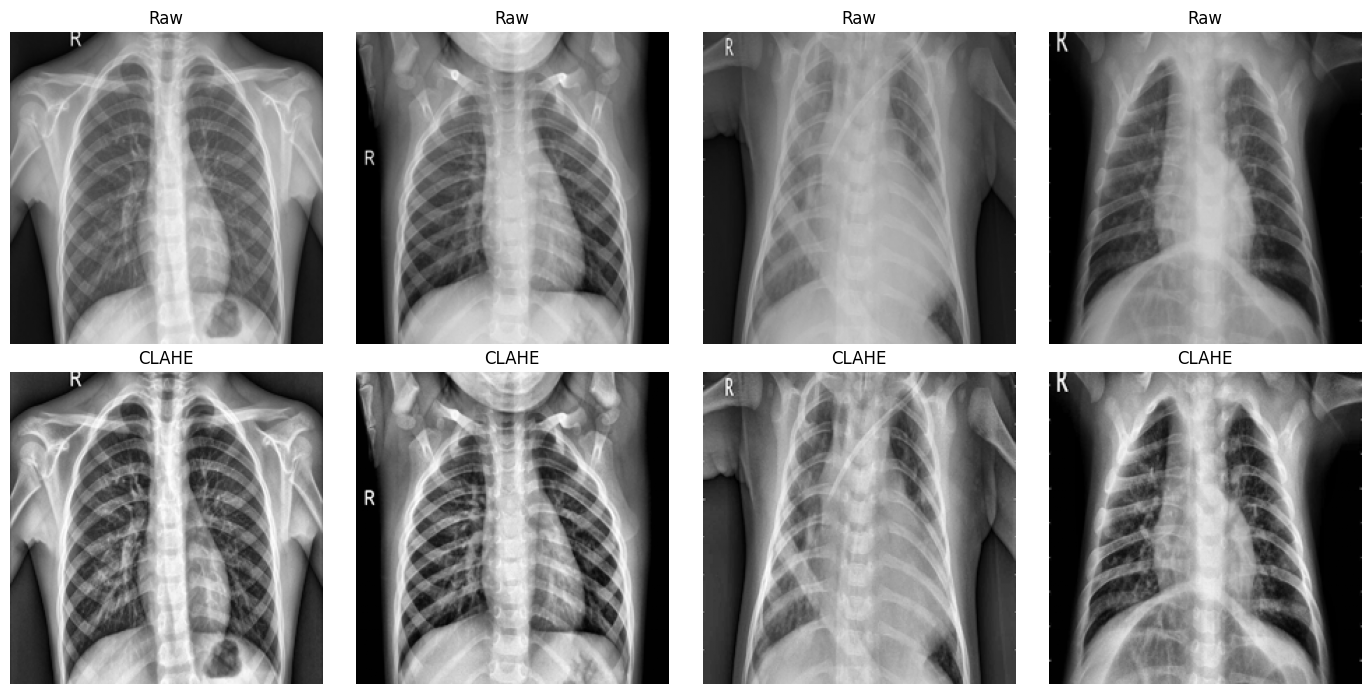

In [ ]:
def apply_clahe(gray_np):
    return cv2.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=CLAHE_TILE).apply(gray_np)

class XrayDS(Dataset):
    def __init__(self, paths, labels, use_clahe=False, train=False):
        self.paths, self.labels, self.use_clahe = paths, labels, use_clahe
        self.aug = T.Compose([T.RandomHorizontalFlip(), T.RandomRotation(10)]) if train else T.Compose([])
        self.to_tensor = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("L").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        arr = np.array(img)
        if self.use_clahe:
            arr = apply_clahe(arr)
        img = Image.fromarray(arr).convert("RGB")
        img = self.aug(img)
        return self.to_tensor(img), self.labels[i]

def make_loader(paths, labels, use_clahe, train, bs):
    return DataLoader(XrayDS(paths, labels, use_clahe, train), batch_size=bs, shuffle=train,
                      num_workers=2, pin_memory=use_cuda)

# Visual check: raw vs CLAHE
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for j in range(4):
    img = Image.open(te_p[j * 150]).convert("L").resize((IMG_SIZE, IMG_SIZE))
    ax[0, j].imshow(img, cmap="gray"); ax[0, j].set_title("Raw"); ax[0, j].axis("off")
    ax[1, j].imshow(apply_clahe(np.array(img)), cmap="gray"); ax[1, j].set_title("CLAHE"); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

## 5. Evaluation metrics

The evaluation function reports accuracy, precision, recall/sensitivity, specificity, F1, and ROC AUC, along with confusion-matrix counts. `PNEUMONIA` is treated as the positive class, and the prediction threshold is 0.5.

In [ ]:
@torch.no_grad()
def evaluate(model, loader, name):
    model.eval()
    probs, ys = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_cuda):
            logits = model(pixel_values=x).logits
        probs.append(torch.softmax(logits.float(), dim=1)[:, POS].cpu().numpy())
        ys.append((y == POS).numpy().astype(int))
    probs, ys = np.concatenate(probs), np.concatenate(ys)
    PRED[name.split('.')[0].strip()] = dict(probs=probs, ys=ys)      # kept for the paired analyses in Sections 14-19
    preds = (probs >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(ys, preds).ravel()
    res = dict(model=name,
               accuracy=(tp + tn) / len(ys),
               precision=tp / max(tp + fp, 1),
               recall=tp / max(tp + fn, 1),          # sensitivity
               specificity=tn / max(tn + fp, 1),
               f1=2 * tp / max(2 * tp + fp + fn, 1),
               auc=roc_auc_score(ys, probs),
               tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))
    print(f"{name}\n  Acc {res['accuracy']:.4f} | Prec {res['precision']:.4f} | Recall {res['recall']:.4f} | "
          f"Spec {res['specificity']:.4f} | F1 {res['f1']:.4f} | AUC {res['auc']:.4f}\n  TN={tn} FP={fp} FN={fn} TP={tp}")
    return res

results = []

def cleanup():
    gc.collect()
    if use_cuda:
        torch.cuda.empty_cache()

### Shared state and helpers for the extra analyses
`PRED` stores the test-set probabilities of every experiment so that paired tests can be run later. `VALPROBS` stores validation-set probabilities, which are the only data used to choose thresholds and fusion weights. The TTA views are defined here: each is applied to the normalised tensor (horizontal flip; centre rotation by +5 or -5 degrees with bilinear interpolation and zero fill in normalised space).

In [ ]:
PRED = {}        # test-set probabilities per experiment: PRED["A"] = dict(probs=..., ys=...)
VALPROBS = {}    # validation-set probabilities per model (used for thresholds / calibration / fusion weights)
HIST = {}        # fine-tuning loss histories
VAL_YS = (np.array(va_lm) == POS).astype(int)

import torchvision.transforms.functional as TF
identity = lambda x: x
hflip    = lambda x: torch.flip(x, dims=[3])
rot_p5   = lambda x: TF.rotate(x, 5,  interpolation=TF.InterpolationMode.BILINEAR)
rot_m5   = lambda x: TF.rotate(x, -5, interpolation=TF.InterpolationMode.BILINEAR)
TTA_VIEWS = [identity, hflip, rot_p5, rot_m5]

@torch.no_grad()
def get_probs(model, loader, views):
    model.eval(); out, ys = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        ps = []
        for v in views:
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_cuda):
                logits = model(pixel_values=v(x)).logits
            ps.append(torch.softmax(logits.float(), dim=1)[:, POS])
        out.append(torch.stack(ps).mean(0).cpu().numpy())
        ys.append((y == POS).numpy().astype(int))
    return np.concatenate(out), np.concatenate(ys)

val_raw   = make_loader(va_p, va_lm, use_clahe=False, train=False, bs=EVAL_BATCH)
val_clahe = make_loader(va_p, va_lm, use_clahe=True,  train=False, bs=EVAL_BATCH)

## 6. Experiment A - reference checkpoint, raw images

This checkpoint is downloaded as-is and is **not fine-tuned by this notebook**. It is evaluated on the held-out test folder as a reference baseline. Experiment A2 evaluates the same checkpoint with CLAHE preprocessing.

In [ ]:
ref_model = AutoModelForImageClassification.from_pretrained(MODEL_NAME, revision=MODEL_REV).to(device)
print("Parameters:", f"{sum(p.numel() for p in ref_model.parameters()):,}")

test_raw = make_loader(te_p, te_lm, use_clahe=False, train=False, bs=EVAL_BATCH)
results.append(evaluate(ref_model, test_raw, "A. Reference ViT (zero-shot, raw)"))

# A2: same model, CLAHE applied only at inference time
test_clahe = make_loader(te_p, te_lm, use_clahe=True, train=False, bs=EVAL_BATCH)
results.append(evaluate(ref_model, test_clahe, "A2. Reference ViT (zero-shot, CLAHE input)"))

# validation-set probabilities (used only for thresholds, calibration and the fusion-weight analysis)
VALPROBS["A"] = get_probs(ref_model, val_raw, [identity])[0]
VALPROBS["A_clahe"] = get_probs(ref_model, val_clahe, [identity])[0]

del ref_model; cleanup()

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Parameters: 85,800,194
A. Reference ViT (zero-shot, raw)
  Acc 0.9728 | Prec 0.9746 | Recall 0.9821 | Spec 0.9573 | F1 0.9783 | AUC 0.9976
  TN=224 FP=10 FN=7 TP=383
A2. Reference ViT (zero-shot, CLAHE input)
  Acc 0.9631 | Prec 0.9599 | Recall 0.9821 | Spec 0.9316 | F1 0.9708 | AUC 0.9917
  TN=218 FP=16 FN=7 TP=383


## 7. Fine-tuning function

The following function fine-tunes the existing reference checkpoint on the notebook's training split. Configurable changes include class-weighted cross-entropy and optional CLAHE preprocessing.

Training uses AdamW, a cosine schedule with warmup, mixed precision when CUDA is available, gradient clipping, early stopping on validation loss, and best weights stored on CPU to reduce GPU memory pressure. The checkpoint is already task-fine-tuned, so this is adaptation rather than training a ViT from scratch.

In [ ]:
def finetune(use_clahe, tag, use_weights=True, seed=None, data=None):
    if seed is not None:
        set_seed(seed)                       # fixed seed for the repeated-seed experiments
    _tr_p, _tr_lm, _va_p, _va_lm = data if data is not None else (tr_p, tr_lm, va_p, va_lm)
    model = AutoModelForImageClassification.from_pretrained(MODEL_NAME, revision=MODEL_REV).to(device)
    train_loader = make_loader(_tr_p, _tr_lm, use_clahe, True, BATCH_SIZE)
    val_loader   = make_loader(_va_p, _va_lm, use_clahe, False, EVAL_BATCH)

    counts = np.bincount(_tr_lm, minlength=2)
    if use_weights:
        w = counts.sum() / (2.0 * counts)                   # inverse-frequency class weights (model label space)
        print(f"[{tag}] class weights (model id order): {np.round(w, 4)}")
        criterion = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=device))
    else:
        print(f"[{tag}] NO class weights (plain cross-entropy)")
        criterion = nn.CrossEntropyLoss()

    opt = torch.optim.AdamW(model.parameters(), lr=FT_LR, weight_decay=WEIGHT_DECAY)
    total_steps = FT_EPOCHS * len(train_loader)
    sched = get_cosine_schedule_with_warmup(opt, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)

    hist = dict(train_loss=[], val_loss=[], val_acc=[])
    best_val, best_state, bad = float("inf"), None, 0

    for ep in range(1, FT_EPOCHS + 1):
        t0 = time.time(); model.train(); run, n = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_cuda):
                loss = criterion(model(pixel_values=x).logits.float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run += loss.item() * x.size(0); n += x.size(0)

        model.eval(); vl, vc, vn = 0.0, 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_cuda):
                    out = model(pixel_values=x).logits.float()
                vl += criterion(out, y).item() * x.size(0)
                vc += (out.argmax(1) == y).sum().item(); vn += x.size(0)
        tl, vl, va = run / n, vl / vn, vc / vn
        hist["train_loss"].append(tl); hist["val_loss"].append(vl); hist["val_acc"].append(va)
        print(f"[{tag}] epoch {ep}/{FT_EPOCHS} | train_loss {tl:.4f} | val_loss {vl:.4f} | val_acc {va:.4f} | {time.time()-t0:.0f}s")

        if vl < best_val:
            best_val, bad = vl, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= FT_PATIENCE:
                print(f"[{tag}] early stopping at epoch {ep}"); break

    model.load_state_dict(best_state)
    if max(hist["val_acc"]) < MIN_VAL_ACC:
        print(f"[{tag}] WARNING: validation accuracy never reached {MIN_VAL_ACC} - this run failed, re-run it.")
    return model, hist

def plot_hist(h, title):
    plt.figure(figsize=(6, 3.5))
    plt.plot(h["train_loss"], label="train loss"); plt.plot(h["val_loss"], label="val loss")
    plt.title(title); plt.xlabel("epoch"); plt.legend(); plt.tight_layout(); plt.show()

## 8. Experiment B - fine-tuning with class-weighted loss

Fine-tune on raw images using inverse-frequency class weights.

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[B] class weights (model id order): [1.9447 0.673 ]
[B] epoch 1/5 | train_loss 0.0770 | val_loss 0.0271 | val_acc 0.9949 | 86s
[B] epoch 2/5 | train_loss 0.0529 | val_loss 0.0252 | val_acc 0.9936 | 63s
[B] epoch 3/5 | train_loss 0.0370 | val_loss 0.0315 | val_acc 0.9859 | 63s
[B] epoch 4/5 | train_loss 0.0264 | val_loss 0.0176 | val_acc 0.9974 | 64s
[B] epoch 5/5 | train_loss 0.0143 | val_loss 0.0181 | val_acc 0.9974 | 64s


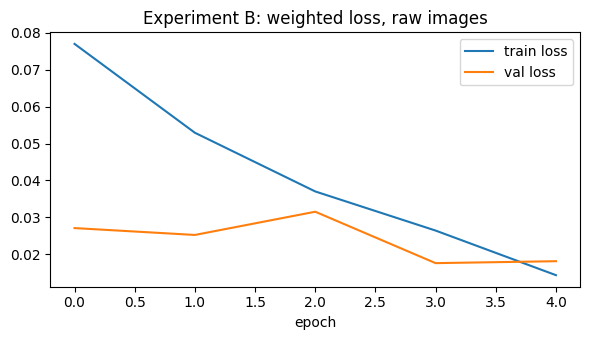

B. ViT fine-tuned (our split + class weights)
  Acc 0.8942 | Prec 0.8568 | Recall 0.9974 | Spec 0.7222 | F1 0.9218 | AUC 0.9914
  TN=169 FP=65 FN=1 TP=389


In [ ]:
model_b, hist_b = finetune(use_clahe=False, tag="B")
plot_hist(hist_b, "Experiment B: weighted loss, raw images")
results.append(evaluate(model_b, test_raw, "B. ViT fine-tuned (our split + class weights)"))
VALPROBS["B"] = get_probs(model_b, val_raw, [identity])[0]; HIST["B"] = hist_b
del model_b; cleanup()

## 8b. Experiment B2 - fine-tuning without class weights

This ablation uses the same split and fine-tuning setup as B, but uses ordinary cross-entropy. Comparing B and B2 helps assess the effect of class weighting; it does not establish causality beyond this experimental setup.

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[B2] NO class weights (plain cross-entropy)
[B2] epoch 1/5 | train_loss 0.0602 | val_loss 0.1235 | val_acc 0.9629 | 64s
[B2] epoch 2/5 | train_loss 0.0553 | val_loss 0.0406 | val_acc 0.9910 | 64s
[B2] epoch 3/5 | train_loss 0.0332 | val_loss 0.0363 | val_acc 0.9910 | 65s
[B2] epoch 4/5 | train_loss 0.0242 | val_loss 0.0252 | val_acc 0.9923 | 64s
[B2] epoch 5/5 | train_loss 0.0137 | val_loss 0.0183 | val_acc 0.9936 | 64s


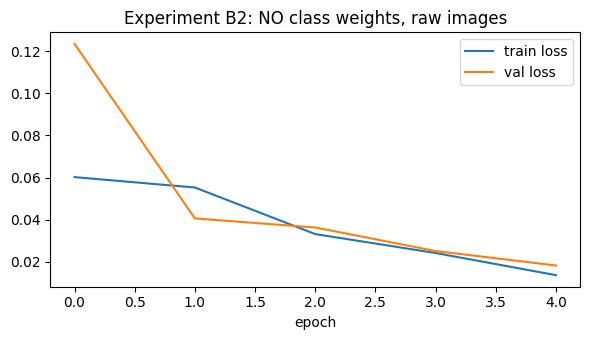

B2. ViT fine-tuned (our split, NO class weights)
  Acc 0.9054 | Prec 0.8702 | Recall 0.9974 | Spec 0.7521 | F1 0.9295 | AUC 0.9920
  TN=176 FP=58 FN=1 TP=389


In [ ]:
model_b2, hist_b2 = finetune(use_clahe=False, tag="B2", use_weights=False)
plot_hist(hist_b2, "Experiment B2: NO class weights, raw images")
results.append(evaluate(model_b2, test_raw, "B2. ViT fine-tuned (our split, NO class weights)"))
VALPROBS["B2"] = get_probs(model_b2, val_raw, [identity])[0]; HIST["B2"] = hist_b2
del model_b2; cleanup()

## 9. Experiment C - fine-tuning with class weights and CLAHE

This experiment combines weighted loss with CLAHE preprocessing.

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[C] class weights (model id order): [1.9447 0.673 ]
[C] epoch 1/5 | train_loss 0.0911 | val_loss 0.0595 | val_acc 0.9885 | 67s
[C] epoch 2/5 | train_loss 0.0794 | val_loss 0.0385 | val_acc 0.9910 | 67s
[C] epoch 3/5 | train_loss 0.0444 | val_loss 0.0379 | val_acc 0.9898 | 67s
[C] epoch 4/5 | train_loss 0.0255 | val_loss 0.0472 | val_acc 0.9847 | 69s
[C] epoch 5/5 | train_loss 0.0212 | val_loss 0.0410 | val_acc 0.9885 | 84s
[C] early stopping at epoch 5


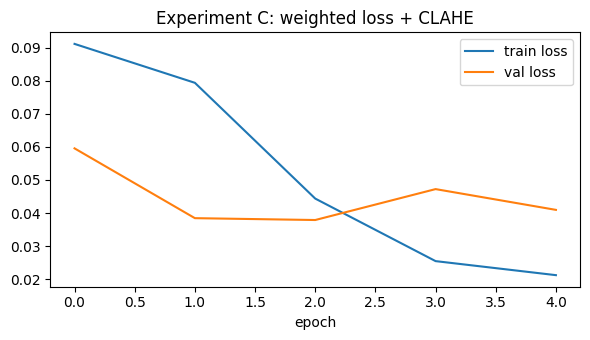

C. ViT fine-tuned (class weights + CLAHE)
  Acc 0.8846 | Prec 0.8457 | Recall 0.9974 | Spec 0.6966 | F1 0.9153 | AUC 0.9858
  TN=163 FP=71 FN=1 TP=389


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
model_c, hist_c = finetune(use_clahe=True, tag="C")
plot_hist(hist_c, "Experiment C: weighted loss + CLAHE")
results.append(evaluate(model_c, test_clahe, "C. ViT fine-tuned (class weights + CLAHE)"))
VALPROBS["C"] = get_probs(model_c, val_clahe, [identity])[0]; HIST["C"] = hist_c

os.makedirs("/content/vit_final", exist_ok=True)
model_c.save_pretrained("/content/vit_final"); processor.save_pretrained("/content/vit_final")
del model_c; cleanup()

## 9b. Experiments D, E, and F - inference-time add-ons

These experiments reload the **unchanged reference checkpoint** and do not retrain it.

| Experiment | Strategy | Description |
|---|---|---|
| D | Test-time augmentation (TTA) | Average predictions across the original image, horizontal flip, +5° rotation, and −5° rotation |
| E | Raw/CLAHE fusion | Average predictions from raw and CLAHE-preprocessed inputs |
| F | Fusion + TTA | Combine both inference-time strategies |

All variants are reported for transparency. Since they are evaluated on the same test set, use caution when interpreting small differences and avoid treating the best test score as an unbiased model-selection result.

In [ ]:
ref_model = AutoModelForImageClassification.from_pretrained(MODEL_NAME, revision=MODEL_REV).to(device).eval()

def metrics_from_probs(probs, ys, name):
    key = name.split(".")[0].strip()
    PRED[key] = dict(probs=np.asarray(probs), ys=np.asarray(ys))
    preds = (probs >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(ys, preds).ravel()
    res = dict(model=name,
               accuracy=(tp + tn) / len(ys),
               precision=tp / max(tp + fp, 1),
               recall=tp / max(tp + fn, 1),
               specificity=tn / max(tn + fp, 1),
               f1=2 * tp / max(2 * tp + fp + fn, 1),
               auc=roc_auc_score(ys, probs),
               tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))
    print(f"{name}\n  Acc {res['accuracy']:.4f} | Prec {res['precision']:.4f} | Recall {res['recall']:.4f} | "
          f"Spec {res['specificity']:.4f} | F1 {res['f1']:.4f} | AUC {res['auc']:.4f}\n  TN={tn} FP={fp} FN={fn} TP={tp}")
    return res

# Probabilities for each view family (test loaders are not shuffled, so rows line up)
p_raw_1,   ys = get_probs(ref_model, test_raw,   [identity])
p_raw_tta, _  = get_probs(ref_model, test_raw,   TTA_VIEWS)
p_cl_1,    _  = get_probs(ref_model, test_clahe, [identity])
p_cl_tta,  _  = get_probs(ref_model, test_clahe, TTA_VIEWS)

results.append(metrics_from_probs(p_raw_tta, ys, "D. Reference ViT + TTA (no retraining)"))
results.append(metrics_from_probs((p_raw_1 + p_cl_1) / 2, ys, "E. Reference ViT + raw/CLAHE fusion (no retraining)"))
results.append(metrics_from_probs((p_raw_tta + p_cl_tta) / 2, ys, "F. Reference ViT + raw/CLAHE fusion + TTA (no retraining)"))

del ref_model; cleanup()

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

D. Reference ViT + TTA (no retraining)
  Acc 0.9760 | Prec 0.9723 | Recall 0.9897 | Spec 0.9530 | F1 0.9809 | AUC 0.9975
  TN=223 FP=11 FN=4 TP=386
E. Reference ViT + raw/CLAHE fusion (no retraining)
  Acc 0.9792 | Prec 0.9772 | Recall 0.9897 | Spec 0.9615 | F1 0.9834 | AUC 0.9963
  TN=225 FP=9 FN=4 TP=386
F. Reference ViT + raw/CLAHE fusion + TTA (no retraining)
  Acc 0.9696 | Prec 0.9603 | Recall 0.9923 | Spec 0.9316 | F1 0.9760 | AUC 0.9965
  TN=218 FP=16 FN=3 TP=387


## 10. Results - metrics, plots, and CNN comparison

The table and plots below summarize the experiments run above. CNN values are copied from earlier project notebooks and are included for context; comparisons are only fair if the evaluation sets and protocols match.

,model,accuracy,precision,recall,specificity,f1,auc
0,"A. Reference ViT (zero-shot, raw)",0.9728,0.9746,0.9821,0.9573,0.9783,0.9976
1,"A2. Reference ViT (zero-shot, CLAHE input)",0.9631,0.9599,0.9821,0.9316,0.9708,0.9917
2,B. ViT fine-tuned (our split + class weights),0.8942,0.8568,0.9974,0.7222,0.9218,0.9914
3,"B2. ViT fine-tuned (our split, NO class weights)",0.9054,0.8702,0.9974,0.7521,0.9295,0.9920
4,C. ViT fine-tuned (class weights + CLAHE),0.8846,0.8457,0.9974,0.6966,0.9153,0.9858
5,D. Reference ViT + TTA (no retraining),0.9760,0.9723,0.9897,0.9530,0.9809,0.9975
6,E. Reference ViT + raw/CLAHE fusion (no retrai...,0.9792,0.9772,0.9897,0.9615,0.9834,0.9963
7,F. Reference ViT + raw/CLAHE fusion + TTA (no ...,0.9696,0.9603,0.9923,0.9316,0.9760,0.9965


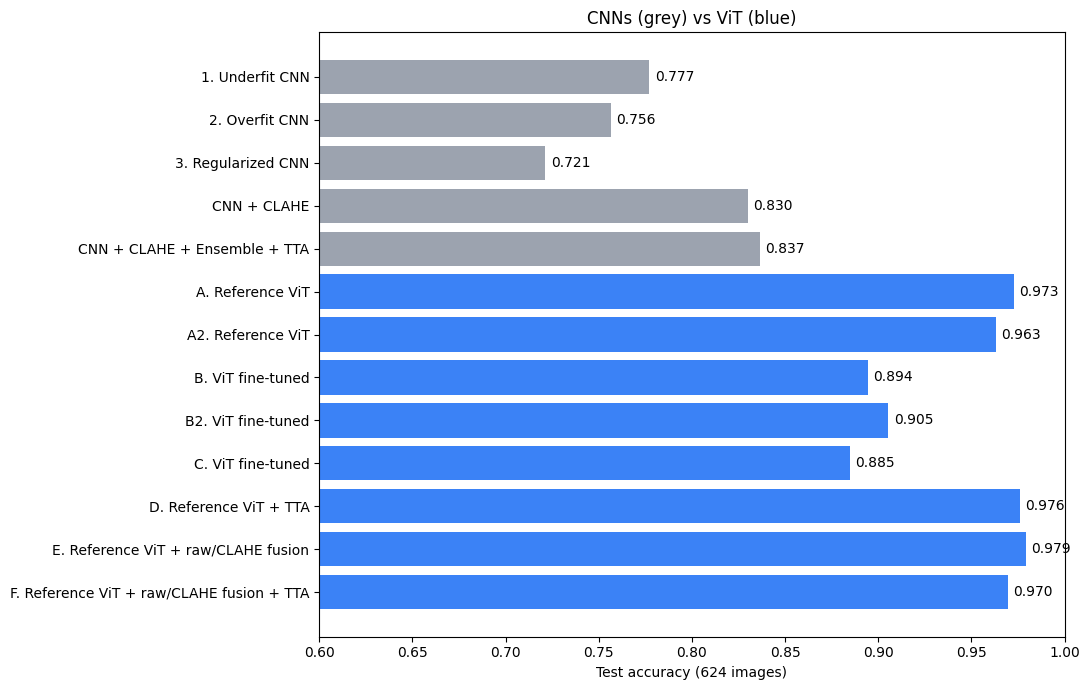

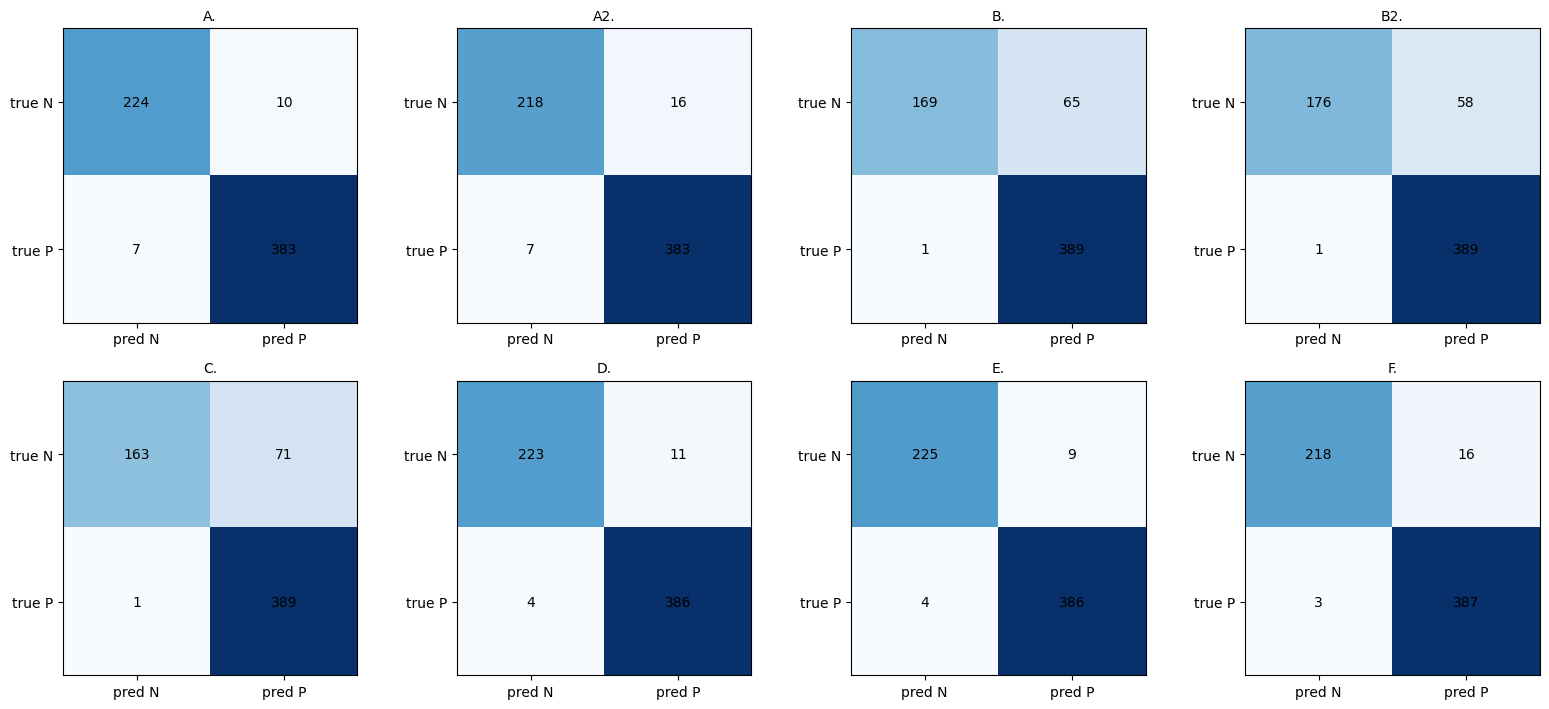

In [ ]:
df = pd.DataFrame(results)
show = df[["model", "accuracy", "precision", "recall", "specificity", "f1", "auc"]].round(4)
display(show)

os.makedirs("/content/results", exist_ok=True)
df.to_csv("/content/results/vit_results.csv", index=False)
json.dump(results, open("/content/results/vit_results.json", "w"), indent=2)

# Comparison with our earlier CNN notebooks (test accuracy values taken from notebooks 01-04 outputs)
cnn_prev = {"1. Underfit CNN": 0.7772, "2. Overfit CNN": 0.7564, "3. Regularized CNN": 0.7212,
            "CNN + CLAHE": 0.8301, "CNN + CLAHE + Ensemble + TTA": 0.8365}
labels = list(cnn_prev.keys()) + [r["model"].split("(")[0].strip() for r in results]
vals   = list(cnn_prev.values()) + [r["accuracy"] for r in results]
colors = ["#9ca3af"] * len(cnn_prev) + ["#3b82f6"] * len(results)

plt.figure(figsize=(11, 7))
bars = plt.barh(labels[::-1], vals[::-1], color=colors[::-1])
for b, v in zip(bars, vals[::-1]):
    plt.text(v + 0.003, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center")
plt.xlim(0.6, 1.0); plt.xlabel("Test accuracy (624 images)")
plt.title("CNNs (grey) vs ViT (blue)"); plt.tight_layout(); plt.show()

# Confusion matrices
ncols = 4; nrows = int(np.ceil(len(results) / ncols))
fig, ax = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.6 * nrows))
ax = np.atleast_1d(ax).ravel()
for a in ax[len(results):]:
    a.axis("off")
for a, r in zip(ax, results):
    cm = np.array([[r["tn"], r["fp"]], [r["fn"], r["tp"]]])
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a.text(j, i, cm[i, j], ha="center", va="center")
    a.set_xticks([0, 1]); a.set_xticklabels(["pred N", "pred P"]); a.set_yticks([0, 1]); a.set_yticklabels(["true N", "true P"])
    a.set_title(r["model"].split(".")[0] + ".", fontsize=10)
plt.tight_layout(); plt.show()

## 11. Literature reference points

The figures below were reported by the cited methods under their own experimental protocols. They are contextual reference points, **not a like-for-like benchmark** against this notebook's test set. Verify the original papers and model card before reusing these values in a formal report.

| Method | Reported accuracy |
|---|---:|
| Kermany et al. (2018) | 92.8% |
| VGG16 transfer learning | 96.6% |
| ResNet + AdaBoost-SVM hybrid | 98.1% |
| CLAHE-enhanced CNN | 98.7% |
| `lxyuan/vit-xray-pneumonia-classification` (model card validation split) | 97.4% |

## 12. Discussion checklist

- **Reference vs. fine-tuned variants:** compare A, B, and C across accuracy, recall, and specificity.
- **B vs. B2:** discuss the observed effect of using class weights in this setup.
- **D, E, and F:** describe the inference-time changes and compare each against A. Do not overstate small differences on a 624-image test set.
- **ViT vs. CNN:** note that the ViT checkpoint uses pretraining, while the earlier CNNs were trained from scratch; this is not an equal initialization comparison.
- **Potential data leakage:** the reference checkpoint may have been trained on a copy of this public dataset. Rows A–F use that checkpoint, so their scores are not guaranteed to be leakage-free.
- **Test-set uncertainty:** the test set is relatively small and may differ in distribution from the training split.
- **Sensitivity and specificity:** explain the trade-off between missed pneumonia cases (false negatives) and false alarms (false positives). This notebook is not a clinical tool.

## 13. Attribution and responsible use

- **Reference model:** [`lxyuan/vit-xray-pneumonia-classification`](https://huggingface.co/lxyuan/vit-xray-pneumonia-classification), whose model card identifies its license and upstream backbone.
- **Backbone:** [`google/vit-base-patch16-224-in21k`](https://huggingface.co/google/vit-base-patch16-224-in21k).
- **Dataset:** [Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia), associated with Kermany et al. (2018), *Identifying Medical Diagnoses and Treatable Diseases by Image-Based Deep Learning*, *Cell*.
- **Notebook modifications:** data split, fine-tuning experiments, optional class weighting and CLAHE, metric reporting, TTA, and raw/CLAHE fusion.

Check the current dataset and model-card license terms before redistributing data, model weights, or derivative artifacts. Code licensing does not automatically license third-party images or pretrained weights.


## 12. Reproducibility record
Records the software environment, the exact checkpoint revision used, and a manifest of every image assigned to train, validation and test (relative path, label, SHA-256 of the file and a **filename-derived patient proxy**).

The proxy is parsed from Kaggle file names: `personN_bacteria|virus_...` for pneumonia, `IM-####-...` and `NORMAL2-IM-####-...` for normal images. It is a proxy, not a verified patient identifier, and it has one important limit: **the numbering restarts between the Kaggle train and test folders** (every pneumonia number that occurs in both folders has a different infection type in each, so those matches are not the same patient). The proxy is therefore used only to compare partitions drawn from the *same* folder (training versus validation), never train versus test.

TTA and CLAHE implementation details used throughout: CLAHE = `cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))` on the 224x224 grayscale image; resizing = PIL bilinear; TTA = identity, horizontal flip, +5 and -5 degree rotations (`torchvision.transforms.functional.rotate`, bilinear, centre, zero fill) applied to the normalised tensor; the PNEUMONIA softmax probability is averaged across views before thresholding at 0.5.

In [ ]:
import sys, platform, re, hashlib, importlib.metadata as imd
RESULTS_DIR = "/content/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

def patient_proxy(path):
    """Filename-derived patient proxy (Kaggle chest X-ray dataset). Meaningful only within one Kaggle folder. None if unrecognised."""
    b = os.path.basename(path)
    m = re.match(r"person(\d+)_(bacteria|virus)_", b, flags=re.I)
    if m:
        return f"person{m.group(1)}_{m.group(2).lower()}"
    m = re.match(r"NORMAL2-IM-(\d+)", b, flags=re.I)
    if m:
        return "N2-IM-" + m.group(1)
    m = re.match(r"IM-(\d+)", b, flags=re.I)
    if m:
        return "IM-" + m.group(1)
    return None

def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def _ver(pkg):
    try:
        return imd.version(pkg)
    except Exception:
        return "n/a"

In [ ]:
ENV = dict(python=sys.version.split()[0], platform=platform.platform(), torch=torch.__version__,
           cuda=torch.version.cuda, gpu=(torch.cuda.get_device_name(0) if use_cuda else None),
           transformers=_ver("transformers"), torchvision=_ver("torchvision"), opencv=cv2.__version__,
           scikit_learn=_ver("scikit-learn"), scipy=_ver("scipy"), numpy=np.__version__, pandas=pd.__version__,
           pillow=_ver("pillow"), huggingface_hub=_ver("huggingface_hub"))
print(json.dumps(ENV, indent=2))
print("Checkpoint:", MODEL_NAME, "| revision:", MODEL_REV)

rows = []
for part, pp, ll in [("train", tr_p, tr_l), ("val", va_p, va_l), ("test", te_p, te_l)]:
    for p, l in zip(pp, ll):
        rows.append(dict(partition=part, rel_path=os.path.relpath(p, root), label=CLASS_NAMES[l],
                         patient_proxy=patient_proxy(p), sha256=sha256_file(p)))
manifest = pd.DataFrame(rows)
manifest.to_csv(f"{RESULTS_DIR}/split_manifest.csv", index=False)
print(manifest.groupby("partition").size().to_dict(), "images hashed")

RUN_MANIFEST = dict(
    run_id=RUN_ID, seed=SEED, model=MODEL_NAME, model_revision=MODEL_REV, environment=ENV,
    split=dict(train=len(tr_p), val=len(va_p), test=len(te_p), val_size_arg=782, stratified=True),
    preprocessing=dict(img_size=IMG_SIZE, clahe_clip=CLAHE_CLIP, clahe_tile=list(CLAHE_TILE), mean=list(MEAN), std=list(STD)),
    finetune=dict(epochs=FT_EPOCHS, patience=FT_PATIENCE, lr=FT_LR, weight_decay=WEIGHT_DECAY, batch=BATCH_SIZE,
                  eval_batch=EVAL_BATCH, optimizer="AdamW", schedule="cosine, 10% warmup", grad_clip=1.0, amp=use_cuda),
    tta_views=["identity", "hflip", "rot+5", "rot-5"], threshold=0.5)
json.dump(RUN_MANIFEST, open(f"{RESULTS_DIR}/run_manifest.json", "w"), indent=2)

{
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "torch": "2.11.0+cu130",
  "cuda": "13.0",
  "gpu": "Tesla T4",
  "transformers": "5.20.2",
  "torchvision": "0.26.0+cu130",
  "opencv": "5.0.0",
  "scikit_learn": "1.6.1",
  "scipy": "1.16.3",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "pillow": "11.3.0",
  "huggingface_hub": "1.33.0"
}
Checkpoint: lxyuan/vit-xray-pneumonia-classification | revision: 2187224687021e1dac2d850bb18e40b8a6f7bf7b
{'test': 624, 'train': 4434, 'val': 782} images hashed


## 13. Experiment register (what was prespecified and what was exploratory)

| ID | Experiment | Status when its test score was first seen |
|---|---|---|
| A, A2 | Reference checkpoint on raw / CLAHE images | Prespecified baselines |
| B, C | Fine-tuning with class weights (raw / with CLAHE) | Prespecified |
| B2 | Fine-tuning without class weights | **Exploratory**: added after the test scores of B and C had been seen, to separate the effect of class weights |
| D, E, F | TTA, raw/CLAHE fusion, fusion with TTA | Prespecified before their test scores were inspected; all three are reported |
| Sections 14-19 | Per-image predictions, confidence intervals, paired tests, calibration, fusion analysis, audits | **Post hoc**, added after an external critical review. Thresholds and fusion weights are chosen on *validation* data only; the test set is not used for selection |
| Section 20 | Repeated seeds for B, B2, C | Robustness check; its results are not used to select any model |
| Section 21 | Patient-disjoint split | Optional, exploratory |

No hyperparameter was selected using test scores. **Authors: confirm this register matches what actually happened before submission, and edit it if not.**

## 14. Per-image predictions
One row per test image with the probability and predicted class of every experiment. All paired statistics below are computed from this table.

In [ ]:
ALL_KEYS = ["A", "A2", "B", "B2", "C", "D", "E", "F"]
missing = [k for k in ALL_KEYS if k not in PRED]
assert not missing, f"Run the experiment cells first; missing predictions for: {missing}"
ref_ys = PRED["A"]["ys"]
for k in ALL_KEYS:
    assert np.array_equal(PRED[k]["ys"], ref_ys), f"label order mismatch for {k}"
    assert len(PRED[k]["probs"]) == len(te_p)

pred_df = pd.DataFrame({"rel_path": [os.path.relpath(p, root) for p in te_p],
                        "patient_proxy": [patient_proxy(p) for p in te_p],
                        "y_true_pneumonia": ref_ys})
for k in ALL_KEYS:
    pred_df[f"p_{k}"] = PRED[k]["probs"]
    pred_df[f"pred_{k}"] = (PRED[k]["probs"] >= 0.5).astype(int)
pred_df.to_csv(f"{RESULTS_DIR}/predictions_test.csv", index=False)
print("Saved", len(pred_df), "rows x", pred_df.shape[1], "columns")
display(pred_df.head())

Saved 624 rows x 19 columns


,rel_path,patient_proxy,y_true_pneumonia,p_A,pred_A,p_A2,pred_A2,p_B,pred_B,p_B2,pred_B2,p_C,pred_C,p_D,pred_D,p_E,pred_E,p_F,pred_F
0,test/NORMAL/IM-0001-0001.jpeg,IM-0001,0,0.010632,0,0.013637,0,0.003450,0,0.005406,0,0.012171,0,0.011477,0,0.012134,0,0.014928,0
1,test/NORMAL/IM-0003-0001.jpeg,IM-0003,0,0.010966,0,0.029284,0,0.004755,0,0.006327,0,0.004565,0,0.012201,0,0.020125,0,0.028768,0
2,test/NORMAL/IM-0005-0001.jpeg,IM-0005,0,0.011620,0,0.018582,0,0.004382,0,0.006451,0,0.006539,0,0.012353,0,0.015101,0,0.017855,0
3,test/NORMAL/IM-0006-0001.jpeg,IM-0006,0,0.010653,0,0.059210,0,0.003817,0,0.006157,0,0.020449,0,0.012832,0,0.034931,0,0.092809,0
4,test/NORMAL/IM-0007-0001.jpeg,IM-0007,0,0.011288,0,0.014842,0,0.003216,0,0.004512,0,0.004764,0,0.012022,0,0.013065,0,0.020505,0


## 15. Confidence intervals, calibration and predictive values
Accuracy, sensitivity, specificity and precision use 95% Wilson intervals. AUC uses a stratified bootstrap (2,000 resamples). The Brier score and the expected calibration error (ECE, 10 equal-width bins) describe probability quality; they are descriptive and are not used to choose models.

In [ ]:
from scipy.stats import binomtest
rng = np.random.default_rng(SEED)

def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)

def boot_auc_ci(y, p, n_boot=2000):
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    vals = []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        vals.append(roc_auc_score(y[idx], p[idx]))
    return tuple(np.percentile(vals, [2.5, 97.5]))

def ece_score(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1); n = len(y); e = 0.0
    for i in range(bins):
        m = (p >= edges[i]) & ((p < edges[i + 1]) if i < bins - 1 else (p <= edges[i + 1]))
        if m.sum():
            e += m.sum() / n * abs(y[m].mean() - p[m].mean())
    return float(e)

def fmt(v, ci, pct=True):
    s = 100 if pct else 1
    return f"{v*s:.2f} ({ci[0]*s:.2f}-{ci[1]*s:.2f})" if pct else f"{v:.4f} ({ci[0]:.4f}-{ci[1]:.4f})"

rows = []
for k in ALL_KEYS:
    p, y = PRED[k]["probs"], PRED[k]["ys"]; pred = (p >= 0.5).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    fp = int(((pred == 1) & (y == 0)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    auc = roc_auc_score(y, p); auc_ci = boot_auc_ci(y, p)
    rows.append({"ID": k,
                 "Accuracy % (95% CI)": fmt((tp + tn) / len(y), wilson(tp + tn, len(y))),
                 "Sensitivity % (95% CI)": fmt(tp / (tp + fn), wilson(tp, tp + fn)),
                 "Specificity % (95% CI)": fmt(tn / (tn + fp), wilson(tn, tn + fp)),
                 "Precision % (95% CI)": fmt(tp / max(tp + fp, 1), wilson(tp, tp + fp)),
                 "AUC (95% CI)": fmt(auc, auc_ci, pct=False),
                 "Brier": round(float(np.mean((p - y) ** 2)), 4), "ECE": round(ece_score(y, p), 4),
                 "FN": fn, "FP": fp})
ci_df = pd.DataFrame(rows)
ci_df.to_csv(f"{RESULTS_DIR}/metrics_with_ci.csv", index=False)
display(ci_df)

# Predictive values at other prevalences (sensitivity/specificity from the test set; prevalence is an assumption)
pv_rows = []
for k in ALL_KEYS:
    p, y = PRED[k]["probs"], PRED[k]["ys"]; pred = (p >= 0.5).astype(int)
    sens = ((pred == 1) & (y == 1)).sum() / (y == 1).sum(); spec = ((pred == 0) & (y == 0)).sum() / (y == 0).sum()
    for prev in (0.05, 0.15, 0.30, float(y.mean())):
        ppv = sens * prev / (sens * prev + (1 - spec) * (1 - prev)); npv = spec * (1 - prev) / (spec * (1 - prev) + (1 - sens) * prev)
        pv_rows.append(dict(ID=k, prevalence=round(prev, 3), PPV=round(ppv, 4), NPV=round(npv, 4)))
pv_df = pd.DataFrame(pv_rows)
pv_df.to_csv(f"{RESULTS_DIR}/predictive_values.csv", index=False)
display(pv_df.pivot(index="ID", columns="prevalence", values="PPV").round(3).rename_axis("PPV by prevalence"))

,ID,Accuracy % (95% CI),Sensitivity % (95% CI),Specificity % (95% CI),Precision % (95% CI),AUC (95% CI),Brier,ECE,FN,FP
0,A,97.28 (95.68-98.29),98.21 (96.34-99.13),95.73 (92.31-97.66),97.46 (95.38-98.61),0.9976 (0.9952-0.9994),0.0163,0.0213,7,10
1,A2,96.31 (94.53-97.53),98.21 (96.34-99.13),93.16 (89.18-95.75),95.99 (93.59-97.52),0.9917 (0.9854-0.9967),0.0293,0.0208,7,16
2,B,89.42 (86.76-91.60),99.74 (98.56-99.95),72.22 (66.16-77.57),85.68 (82.16-88.61),0.9914 (0.9823-0.9974),0.0955,0.1011,1,65
3,B2,90.54 (87.99-92.60),99.74 (98.56-99.95),75.21 (69.30-80.31),87.02 (83.59-89.83),0.9920 (0.9821-0.9980),0.0876,0.0939,1,58
4,C,88.46 (85.72-90.74),99.74 (98.56-99.95),69.66 (63.49-75.19),84.57 (80.98-87.58),0.9858 (0.9756-0.9933),0.1006,0.1076,1,71
5,D,97.60 (96.07-98.54),98.97 (97.39-99.60),95.30 (91.78-97.36),97.23 (95.11-98.45),0.9975 (0.9949-0.9994),0.0194,0.0298,4,11
6,E,97.92 (96.47-98.78),98.97 (97.39-99.60),96.15 (92.85-97.96),97.72 (95.73-98.80),0.9963 (0.9928-0.9991),0.0196,0.0255,4,9
7,F,96.96 (95.29-98.04),99.23 (97.76-99.74),93.16 (89.18-95.75),96.03 (93.65-97.54),0.9965 (0.9927-0.9991),0.0260,0.0461,3,16


prevalence,0.050,0.150,0.300,0.625
PPV by prevalence,,,,
A,0.547,0.802,0.908,0.975
A2,0.430,0.717,0.860,0.960
B,0.159,0.388,0.606,0.857
B2,0.175,0.415,0.633,0.870
C,0.148,0.367,0.585,0.846
D,0.526,0.788,0.900,0.972
E,0.575,0.820,0.917,0.977
F,0.433,0.719,0.862,0.960


## 16. Paired comparisons
All models are scored on the **same** 624 images, so errors are paired. For each comparison we report images fixed and images broken by the candidate, an exact McNemar test, and paired bootstrap 95% intervals (10,000 resamples of images) for the differences in accuracy, sensitivity and specificity (positives and negatives resampled separately), plus a bootstrap interval for the AUC difference (2,000 resamples). p-values are corrected across the seven prespecified comparisons with the Holm method. The **primary** comparison is E versus A; the others are secondary.

In [ ]:
COMPARISONS = [("E", "A"), ("D", "A"), ("F", "A"), ("A2", "A"), ("B", "A"), ("B2", "B"), ("C", "B")]   # (candidate, reference)

def paired_row(cand, ref, n_boot=10000, n_boot_auc=2000):
    y = ref_ys; pc, pr = PRED[cand]["probs"], PRED[ref]["probs"]
    cc = ((pc >= 0.5).astype(int) == y); cr = ((pr >= 0.5).astype(int) == y)
    fixed = int((~cr & cc).sum()); broken = int((cr & ~cc).sum())
    p_mc = 1.0 if fixed + broken == 0 else float(binomtest(min(fixed, broken), fixed + broken, 0.5).pvalue)
    n = len(y); pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    idx = rng.integers(0, n, (n_boot, n))
    d_acc = cc[idx].mean(1) - cr[idx].mean(1)
    ip = rng.choice(pos, (n_boot, len(pos))); ineg = rng.choice(neg, (n_boot, len(neg)))
    d_sens = cc[ip].mean(1) - cr[ip].mean(1); d_spec = cc[ineg].mean(1) - cr[ineg].mean(1)
    d_auc = []
    for _ in range(n_boot_auc):
        j = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        d_auc.append(roc_auc_score(y[j], pc[j]) - roc_auc_score(y[j], pr[j]))
    q = lambda a: tuple(np.percentile(a, [2.5, 97.5]))
    ci = lambda obs, a: f"{obs*100:+.2f} ({q(a)[0]*100:+.2f} to {q(a)[1]*100:+.2f})"
    obs_sens = cc[pos].mean() - cr[pos].mean(); obs_spec = cc[neg].mean() - cr[neg].mean()
    return {"Candidate": cand, "Reference": ref, "Fixed by candidate": fixed, "Broken by candidate": broken,
            "Net errors removed": fixed - broken,
            "Accuracy diff, pp (95% CI)": ci(cc.mean() - cr.mean(), d_acc),
            "Sensitivity diff, pp (95% CI)": ci(obs_sens, d_sens),
            "Specificity diff, pp (95% CI)": ci(obs_spec, d_spec),
            "AUC diff (95% CI)": f"{roc_auc_score(y, pc) - roc_auc_score(y, pr):+.4f} ({q(d_auc)[0]:+.4f} to {q(d_auc)[1]:+.4f})",
            "McNemar p": p_mc}

paired_df = pd.DataFrame([paired_row(c, r) for c, r in COMPARISONS])
pv = paired_df["McNemar p"].values; order = np.argsort(pv); m = len(pv); adj = np.empty(m); running = 0.0
for rank, i in enumerate(order):
    running = max(running, (m - rank) * pv[i]); adj[i] = min(1.0, running)
paired_df["Holm-adjusted p"] = adj
paired_df.to_csv(f"{RESULTS_DIR}/paired_tests.csv", index=False)
display(paired_df)
print("Primary comparison: E vs A. A comparison is only called significant if its Holm-adjusted p < 0.05 AND its CI excludes 0.")

,Candidate,Reference,Fixed by candidate,Broken by candidate,Net errors removed,"Accuracy diff, pp (95% CI)","Sensitivity diff, pp (95% CI)","Specificity diff, pp (95% CI)",AUC diff (95% CI),McNemar p,Holm-adjusted p
0,E,A,5,1,4,+0.64 (+0.00 to +1.44),+0.77 (+0.00 to +1.79),+0.43 (-0.85 to +2.14),-0.0013 (-0.0029 to -0.0001),2.187500e-01,1.000000e+00
1,D,A,4,2,2,+0.32 (-0.48 to +1.12),+0.77 (+0.00 to +1.79),-0.43 (-2.14 to +0.85),-0.0001 (-0.0007 to +0.0005),6.875000e-01,1.000000e+00
2,F,A,5,7,-2,-0.32 (-1.44 to +0.80),+1.03 (+0.26 to +2.05),-2.56 (-5.13 to -0.43),-0.0011 (-0.0024 to +0.0001),7.744141e-01,1.000000e+00
3,A2,A,5,11,-6,-0.96 (-2.24 to +0.32),+0.00 (-1.28 to +1.28),-2.56 (-5.13 to +0.00),-0.0059 (-0.0103 to -0.0023),2.101135e-01,1.000000e+00
4,B,A,7,56,-49,-7.85 (-10.26 to -5.45),+1.54 (+0.51 to +2.82),-23.50 (-29.06 to -17.95),-0.0062 (-0.0139 to -0.0011),1.363671e-10,9.545700e-10
5,B2,B,11,4,7,+1.12 (+0.00 to +2.40),+0.00 (+0.00 to +0.00),+2.99 (+0.00 to +6.41),+0.0006 (-0.0007 to +0.0021),1.184692e-01,7.108154e-01
6,C,B,10,16,-6,-0.96 (-2.56 to +0.64),+0.00 (+0.00 to +0.00),-2.56 (-6.84 to +1.71),-0.0057 (-0.0094 to -0.0024),3.269396e-01,1.000000e+00


Primary comparison: E vs A. A comparison is only called significant if its Holm-adjusted p < 0.05 AND its CI excludes 0.


## 17. Operating points, ROC and calibration (thresholds chosen on validation data only)
Two operating points are defined **on the validation set**: (i) the threshold maximising Youden's J (sensitivity + specificity - 1); (ii) the threshold with the highest specificity subject to validation sensitivity >= 0.98. Each threshold is then applied once to the test set. The 0.5 threshold is shown for reference. The diagnostics table shows how the average predicted probability and the predicted-positive rate change between validation and test, which tests the idea that fine-tuning learned the training folder's higher pneumonia prevalence.

,ID,operating_point,threshold,val_sens,val_spec,test_sens,test_spec,test_acc,test_FN,test_FP
0,A,0.5 (default),0.5000,0.9742,0.995,0.9821,0.9573,0.9728,7,10
1,A,Youden (val),0.3110,0.9880,0.995,0.9974,0.9487,0.9792,1,12
2,A,Sens>=0.98 (val),0.3917,0.9811,0.995,0.9897,0.9530,0.9760,4,11
3,B,0.5 (default),0.5000,0.9983,0.995,0.9974,0.7222,0.8942,1,65
4,B,Youden (val),0.0815,1.0000,0.995,0.9974,0.6752,0.8766,1,76
5,B,Sens>=0.98 (val),0.5000,0.9983,0.995,0.9974,0.7222,0.8942,1,65
6,B2,0.5 (default),0.5000,0.9931,0.995,0.9974,0.7521,0.9054,1,58
7,B2,Youden (val),0.3622,0.9966,0.995,0.9974,0.7436,0.9022,1,60
8,B2,Sens>=0.98 (val),0.5000,0.9931,0.995,0.9974,0.7521,0.9054,1,58
9,C,0.5 (default),0.5000,0.9880,0.995,0.9974,0.6966,0.8846,1,71


,ID,val_mean_p_on_NORMAL,test_mean_p_on_NORMAL,val_pred_pos_rate,test_pred_pos_rate,val_true_prev,test_true_prev,val_ECE,test_ECE,val_Brier,test_Brier
0,A,0.0187,0.0586,0.7251,0.6298,0.743,0.625,0.0262,0.0213,0.0146,0.0163
1,B,0.0082,0.2775,0.7430,0.7276,0.743,0.625,0.0014,0.1011,0.0024,0.0955
2,B2,0.0104,0.2585,0.7391,0.7163,0.743,0.625,0.0059,0.0939,0.0043,0.0876
3,C,0.0110,0.2974,0.7353,0.7372,0.743,0.625,0.0104,0.1076,0.0097,0.1006
4,E,0.0234,0.0872,0.7276,0.6330,0.743,0.625,0.0395,0.0255,0.0139,0.0196


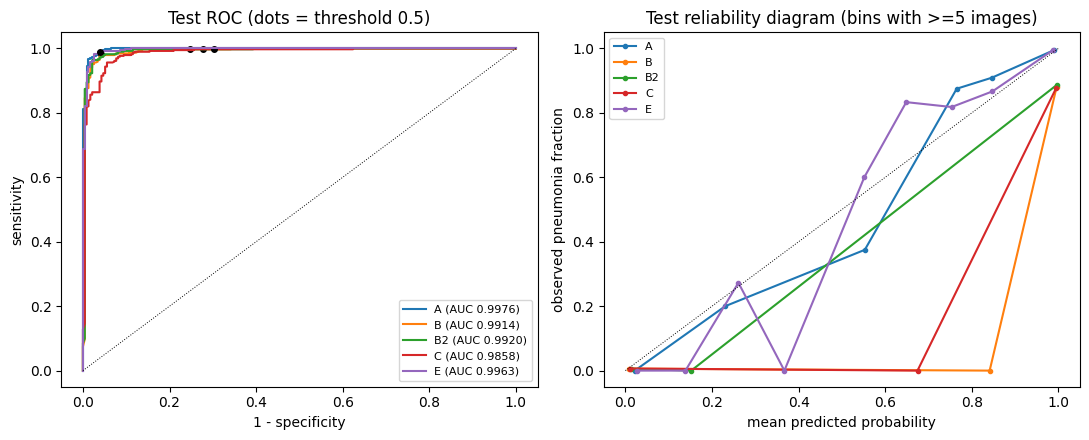

In [ ]:
def op_metrics(y, p, t):
    pred = p >= t
    tp = int((pred & (y == 1)).sum()); tn = int((~pred & (y == 0)).sum())
    fp = int((pred & (y == 0)).sum()); fn = int((~pred & (y == 1)).sum())
    return dict(sens=tp / max(tp + fn, 1), spec=tn / max(tn + fp, 1), acc=(tp + tn) / len(y), fp=fp, fn=fn)

def candidates(p):
    return np.unique(np.concatenate([p, [0.5]]))

def pick_youden(y, p):
    best_t, best_j = 0.5, -1.0
    for t in candidates(p):
        mm = op_metrics(y, p, t); j = mm["sens"] + mm["spec"] - 1
        if j > best_j + 1e-12 or (abs(j - best_j) <= 1e-12 and abs(t - 0.5) < abs(best_t - 0.5)):
            best_t, best_j = float(t), j
    return best_t

def pick_sens(y, p, target=0.98):
    best_t, best_spec = None, -1.0
    for t in candidates(p):
        mm = op_metrics(y, p, t)
        if mm["sens"] >= target and (mm["spec"] > best_spec + 1e-12 or (abs(mm["spec"] - best_spec) <= 1e-12 and abs(t - 0.5) < abs(best_t - 0.5))):
            best_t, best_spec = float(t), mm["spec"]
    return best_t

val_p  = {"A": VALPROBS["A"], "B": VALPROBS["B"], "B2": VALPROBS["B2"], "C": VALPROBS["C"],
          "E": (VALPROBS["A"] + VALPROBS["A_clahe"]) / 2}
test_p = {k: PRED[k]["probs"] for k in val_p}
yv, yt = VAL_YS, ref_ys

rows = []
for k in val_p:
    for label, t in [("0.5 (default)", 0.5), ("Youden (val)", pick_youden(yv, val_p[k])), ("Sens>=0.98 (val)", pick_sens(yv, val_p[k]))]:
        if t is None:
            rows.append(dict(ID=k, operating_point=label, threshold=np.nan)); continue
        v, s = op_metrics(yv, val_p[k], t), op_metrics(yt, test_p[k], t)
        rows.append(dict(ID=k, operating_point=label, threshold=round(t, 4),
                         val_sens=round(v["sens"], 4), val_spec=round(v["spec"], 4),
                         test_sens=round(s["sens"], 4), test_spec=round(s["spec"], 4), test_acc=round(s["acc"], 4),
                         test_FN=s["fn"], test_FP=s["fp"]))
thr_df = pd.DataFrame(rows); thr_df.to_csv(f"{RESULTS_DIR}/threshold_analysis.csv", index=False)
display(thr_df)

# Prior-shift diagnostics: does the model predict "pneumonia" more often than the data warrant?
diag = []
for k in val_p:
    diag.append(dict(ID=k,
        val_mean_p_on_NORMAL=round(float(val_p[k][yv == 0].mean()), 4), test_mean_p_on_NORMAL=round(float(test_p[k][yt == 0].mean()), 4),
        val_pred_pos_rate=round(float((val_p[k] >= 0.5).mean()), 4), test_pred_pos_rate=round(float((test_p[k] >= 0.5).mean()), 4),
        val_true_prev=round(float(yv.mean()), 4), test_true_prev=round(float(yt.mean()), 4),
        val_ECE=round(ece_score(yv, val_p[k]), 4), test_ECE=round(ece_score(yt, test_p[k]), 4),
        val_Brier=round(float(np.mean((val_p[k] - yv) ** 2)), 4), test_Brier=round(float(np.mean((test_p[k] - yt) ** 2)), 4)))
diag_df = pd.DataFrame(diag); diag_df.to_csv(f"{RESULTS_DIR}/prior_shift_calibration.csv", index=False)
display(diag_df)

# ROC curves and reliability diagrams on the test set
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for k in test_p:
    fpr, tpr, _ = roc_curve(yt, test_p[k]); ax[0].plot(fpr, tpr, label=f"{k} (AUC {roc_auc_score(yt, test_p[k]):.4f})")
    s = op_metrics(yt, test_p[k], 0.5); ax[0].plot(1 - s["spec"], s["sens"], "ko", ms=4)
ax[0].plot([0, 1], [0, 1], "k:", lw=0.7); ax[0].set_xlabel("1 - specificity"); ax[0].set_ylabel("sensitivity")
ax[0].set_title("Test ROC (dots = threshold 0.5)"); ax[0].legend(fontsize=8)
edges = np.linspace(0, 1, 11)
for k in test_p:
    xs, ys_ = [], []
    for i in range(10):
        m = (test_p[k] >= edges[i]) & ((test_p[k] < edges[i + 1]) if i < 9 else (test_p[k] <= edges[i + 1]))
        if m.sum() >= 5:
            xs.append(test_p[k][m].mean()); ys_.append(yt[m].mean())
    ax[1].plot(xs, ys_, "-o", ms=3, label=k)
ax[1].plot([0, 1], [0, 1], "k:", lw=0.7); ax[1].set_xlabel("mean predicted probability"); ax[1].set_ylabel("observed pneumonia fraction")
ax[1].set_title("Test reliability diagram (bins with >=5 images)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 18. Does raw/CLAHE fusion add complementary information?
Using the **validation** set, we measure how often the raw-image and CLAHE-image predictions of the reference model agree, how their errors overlap, and how validation accuracy changes with the fusion weight w (fused probability = (1 - w) x raw + w x CLAHE). The prespecified weight is 0.5 (experiment E). A validation-chosen weight is reported for comparison, with the test accuracy shown **descriptively only**.

In [ ]:
pv_raw, pv_cl = VALPROBS["A"], VALPROBS["A_clahe"]

def overlap_table(y, pa, pb, na, nb):
    wa = ((pa >= 0.5).astype(int) != y); wb = ((pb >= 0.5).astype(int) != y)
    return {"both right": int((~wa & ~wb).sum()), f"only {na} wrong": int((wa & ~wb).sum()),
            f"only {nb} wrong": int((~wa & wb).sum()), "both wrong": int((wa & wb).sum()),
            "class agreement": round(float(((pa >= 0.5) == (pb >= 0.5)).mean()), 4),
            "prob. correlation": round(float(np.corrcoef(pa, pb)[0, 1]), 4)}

print("VALIDATION (raw vs CLAHE input to the reference model):", overlap_table(VAL_YS, pv_raw, pv_cl, "raw", "CLAHE"))
print("TEST       (raw vs CLAHE input, descriptive):          ", overlap_table(ref_ys, PRED["A"]["probs"], PRED["A2"]["probs"], "raw", "CLAHE"))

rows = []
for w in np.round(np.linspace(0, 1, 11), 1):
    fv = (1 - w) * pv_raw + w * pv_cl; ft = (1 - w) * PRED["A"]["probs"] + w * PRED["A2"]["probs"]
    rows.append(dict(w=w, val_acc=round(float(((fv >= 0.5).astype(int) == VAL_YS).mean()), 4), val_auc=round(float(roc_auc_score(VAL_YS, fv)), 4),
                     test_acc_descriptive=round(float(((ft >= 0.5).astype(int) == ref_ys).mean()), 4)))
sweep = pd.DataFrame(rows)
best = sweep.assign(d=(sweep.w - 0.5).abs()).sort_values(["val_acc", "d"], ascending=[False, True]).iloc[0]
sweep.to_csv(f"{RESULTS_DIR}/fusion_weight_sweep.csv", index=False)
display(sweep)
print(f"Validation-chosen weight w* = {best.w} (val acc {best.val_acc}); prespecified w = 0.5. Test accuracy at w=0.5: "
      f"{float(sweep.loc[sweep.w == 0.5, 'test_acc_descriptive'].iloc[0]):.4f}; at w*: {float(best.test_acc_descriptive):.4f} (descriptive only).")

# Errors of E relative to its two inputs on the test set (paired)
pe, pa, pc2 = PRED["E"]["probs"], PRED["A"]["probs"], PRED["A2"]["probs"]
wrong = lambda p: ((p >= 0.5).astype(int) != ref_ys)
print("TEST errors: raw", int(wrong(pa).sum()), "| CLAHE", int(wrong(pc2).sum()), "| fusion E", int(wrong(pe).sum()),
      "| fixed vs raw", int((wrong(pa) & ~wrong(pe)).sum()), "| broken vs raw", int((~wrong(pa) & wrong(pe)).sum()))

VALIDATION (raw vs CLAHE input to the reference model): {'both right': 756, 'only raw wrong': 9, 'only CLAHE wrong': 10, 'both wrong': 7, 'class agreement': 0.9757, 'prob. correlation': 0.973}
TEST       (raw vs CLAHE input, descriptive):           {'both right': 596, 'only raw wrong': 5, 'only CLAHE wrong': 11, 'both wrong': 12, 'class agreement': 0.9744, 'prob. correlation': 0.969}


,w,val_acc,val_auc,test_acc_descriptive
0,0.0,0.9795,0.9996,0.9728
1,0.1,0.9783,0.9997,0.9776
2,0.2,0.9795,0.9997,0.9792
3,0.3,0.9795,0.9997,0.9808
4,0.4,0.9821,0.9997,0.9808
5,0.5,0.9821,0.9998,0.9792
6,0.6,0.9770,0.9998,0.9760
7,0.7,0.9770,0.9997,0.9712
8,0.8,0.9783,0.9997,0.9663
9,0.9,0.9783,0.9997,0.9631


Validation-chosen weight w* = 0.5 (val acc 0.9821); prespecified w = 0.5. Test accuracy at w=0.5: 0.9792; at w*: 0.9792 (descriptive only).
TEST errors: raw 17 | CLAHE 23 | fusion E 13 | fixed vs raw 5 | broken vs raw 1


## 19. Audit: patient overlap, duplicates and overlap with the checkpoint's source data
**19a. Training versus validation.** Both come from the Kaggle *train* folder, so the filename-derived patient proxy is meaningful here. We count how many validation images share a proxy with a training image, and search for byte-identical files across partitions. (Train-versus-test patient overlap cannot be assessed from file names, because the numbering restarts in the test folder.)

**19b. Overlap with the checkpoint's source data.** Every image is converted to a 256-bit perceptual hash (DCT of a 64x64 grayscale thumbnail) and compared with the Hugging Face dataset named on the checkpoint's model card (`keremberke/chest-xray-classification`, whose own train / valid / test splits are kept separate). A Kaggle image counts as having a **near-identical copy** in a Hugging Face split if its nearest Hamming distance to that split is at most `NEAR` = 8 bits of 256. The control row shows the distance from each test image to the Kaggle *training* images, which are different X-rays; it should sit far above `NEAR`.

**19c. Does it matter?** Accuracy is compared across three groups of test images: those with a near-identical copy in the Hugging Face **train** split (the split the checkpoint was trained on), those whose copy is only in its **validation** split (which may have influenced model selection), and those whose copy is **only in its test split** (never used for training or selection; the cleanest group, but small). Fisher's exact test compares 'copy in train' with the rest.

**How to read it:** a match is a candidate duplicate, and the closest pairs are displayed for visual checking. Finding no matches would *not* prove independence, and finding matches does not prove the checkpoint trained on those exact files, because its exact training list is not published; but it establishes that the same images are present in the source data.

In [ ]:
def patient_sets(paths):
    return {patient_proxy(p) for p in paths if patient_proxy(p)}

parts = {"train": tr_p, "val": va_p, "test": te_p}
unparsed = {k: sum(1 for p in v if patient_proxy(p) is None) for k, v in parts.items()}
print("file names not recognised:", unparsed)

# training vs validation: both are drawn from the Kaggle TRAIN folder, so the proxy is meaningful
S_tr, S_va = patient_sets(tr_p), patient_sets(va_p)
shared = S_tr & S_va
n_val_shared = sum(1 for p in va_p if patient_proxy(p) in shared)
print(f"Train: {len(S_tr)} proxies | validation: {len(S_va)} proxies | shared: {len(shared)}")
print(f"{n_val_shared} of {len(va_p)} validation images ({n_val_shared / len(va_p):.1%}) share a patient proxy with a training image")
print("Train-versus-test patient overlap cannot be assessed: file numbering restarts in the Kaggle test folder.")
patient_df = pd.DataFrame([dict(comparison="train vs validation (same Kaggle folder)", shared_proxies=len(shared),
                                validation_images_from_shared=n_val_shared, share_of_validation=round(n_val_shared / len(va_p), 4))])
patient_df.to_csv(f"{RESULTS_DIR}/patient_overlap.csv", index=False)

# byte-identical files across partitions (needs the manifest from Section 12)
try:
    grp = manifest.groupby("sha256")["partition"].agg(lambda s: sorted(set(s)))
    cross = grp[grp.apply(len) > 1]
    print("Byte-identical images appearing in more than one partition:", len(cross),
          "| partition pairs:", cross.apply(lambda x: "/".join(x)).value_counts().to_dict())
except NameError:
    print("Run Section 12 first to enable the duplicate check.")

file names not recognised: {'train': 0, 'val': 0, 'test': 0}
Train: 3195 proxies | validation: 696 proxies | shared: 237
309 of 782 validation images (39.5%) share a patient proxy with a training image
Train-versus-test patient overlap cannot be assessed: file numbering restarts in the Kaggle test folder.
Byte-identical images appearing in more than one partition: 8 | partition pairs: {'train/val': 8}


In [ ]:
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

def phash256(gray):
    """256-bit perceptual hash (DCT) of a grayscale uint8 image; returns a packed uint8 vector of length 32."""
    small = cv2.resize(gray, (64, 64), interpolation=cv2.INTER_AREA).astype(np.float32)
    low = cv2.dct(small)[:16, :16].flatten()
    return np.packbits(low > np.median(low[1:]))

def hamming_nn(Q, R, chunk=128, exclude_self=False):
    """For every row of Q (n x 32 uint8) return (min Hamming distance to R, index of nearest row of R)."""
    d_all, i_all = [], []
    for s in range(0, len(Q), chunk):
        q = Q[s:s + chunk]
        d = POP[np.bitwise_xor(q[:, None, :], R[None, :, :])].sum(-1).astype(np.int32)
        if exclude_self:
            for r in range(len(q)):
                d[r, s + r] = 10 ** 6
        d_all.append(d.min(1)); i_all.append(d.argmin(1))
    return np.concatenate(d_all), np.concatenate(i_all)

def hash_paths(paths):
    out = []
    for p in paths:
        g = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
        out.append(phash256(g))
    return np.stack(out)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

11 files in snapshot, e.g.: ['thumbnail.jpg', 'README.md', 'README.dataset.txt', 'chest-xray-classification.py', 'README.roboflow.txt', '.gitattributes', 'split_name_to_num_samples.json', 'data/valid-mini.zip']
Hugging Face images hashed: 5829 {'test': 582, 'train': 4077, 'unknown': 1, 'valid': 1169}


,kaggle_partition,images,median_nn_distance,exact_hash_match,near_identical_copy_in_HF,share
0,test,624,0.0,323,624,1.0
1,val,782,2.0,373,782,1.0
2,train,4434,2.0,2214,4434,1.0


Kaggle TEST images with a near-identical copy (<= 8 bits) in each Hugging Face split:
{
  "test_images": 624,
  "copy_in_HF_train": 445,
  "copy_in_HF_valid": 118,
  "copy_in_HF_test": 61,
  "copy_in_HF_train_or_valid": 563,
  "copy_only_in_HF_test": 61,
  "no_copy_anywhere": 0,
  "share_copy_in_HF_train": 0.7131,
  "share_copy_in_HF_valid": 0.1891,
  "share_copy_in_HF_test": 0.0978,
  "share_copy_in_HF_train_or_valid": 0.9022,
  "share_copy_only_in_HF_test": 0.0978,
  "share_no_copy_anywhere": 0.0
}
Control (test -> Kaggle TRAIN, different X-rays): nearest distance min/5%/median = 42 60.0 72.0 | test -> Hugging Face (any split) median = 0.0


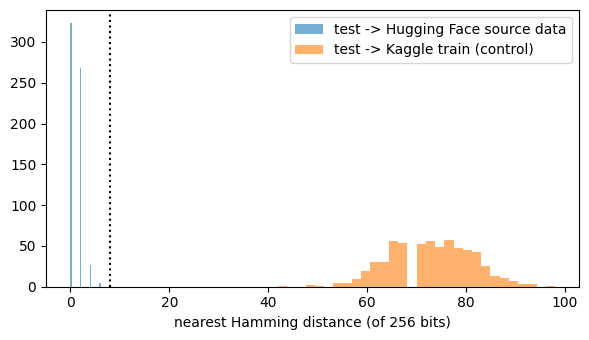

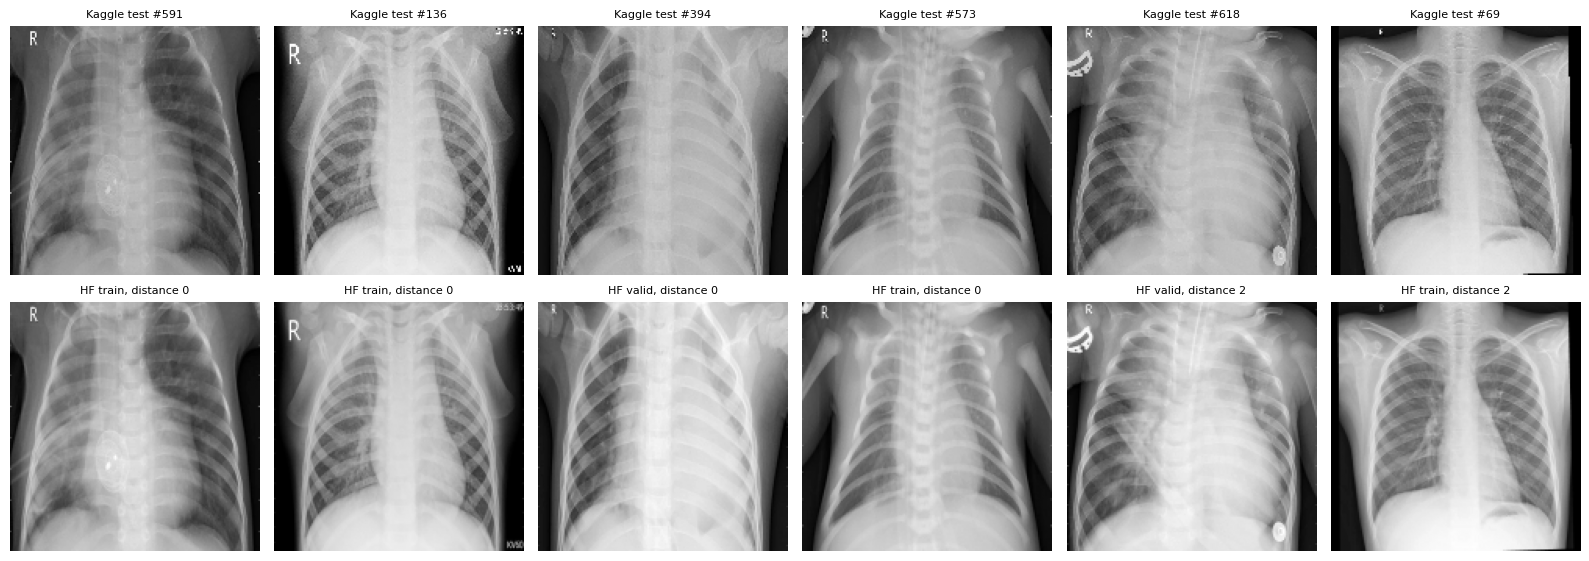

,ID,subset,images,correct,accuracy,ci_low,ci_high,pneumonia_share
0,A,copy in HF train,445,434,0.9753,0.9563,0.9861,0.643
1,A,HF valid only,118,115,0.9746,0.9279,0.9913,0.619
2,A,HF test only (cleanest),61,58,0.9508,0.8651,0.9831,0.508
3,A2,copy in HF train,445,431,0.9685,0.9479,0.9812,0.643
4,A2,HF valid only,118,114,0.9661,0.9161,0.9867,0.619
5,A2,HF test only (cleanest),61,56,0.9180,0.8221,0.9645,0.508
6,D,copy in HF train,445,435,0.9775,0.9591,0.9877,0.643
7,D,HF valid only,118,116,0.9831,0.9403,0.9953,0.619
8,D,HF test only (cleanest),61,58,0.9508,0.8651,0.9831,0.508
9,E,copy in HF train,445,438,0.9843,0.9679,0.9924,0.643


,ID,comparison,fisher_exact_p
0,A,copy in HF train vs no copy in HF train,0.5884
1,A2,copy in HF train vs no copy in HF train,0.2503
2,D,copy in HF train vs no copy in HF train,0.7732
3,E,copy in HF train vs no copy in HF train,0.2119
4,F,copy in HF train vs no copy in HF train,0.4436
5,B,copy in HF train vs no copy in HF train,1.0000
6,B2,copy in HF train vs no copy in HF train,0.3657
7,C,copy in HF train vs no copy in HF train,0.2674


Note: the groups differ in size and class mix; the 'HF test only' group is the one image set never seen by the checkpoint in training or validation, but it is small.


In [ ]:
HF_DATASET = "keremberke/chest-xray-classification"
NEAR = 8                       # bits (of 256) for "near-identical"
import zipfile

def iter_hf_gray():
    """Yield (split, grayscale image) for every image in the Hugging Face dataset. Handles zip, loose-image and parquet layouts."""
    from huggingface_hub import snapshot_download
    local = snapshot_download(repo_id=HF_DATASET, repo_type="dataset")
    files = [os.path.join(dp, f) for dp, _, fs in os.walk(local) for f in fs]
    print(len(files), "files in snapshot, e.g.:", [os.path.relpath(f, local) for f in files[:8]])

    def split_of(s):
        s = s.lower()
        return "train" if "train" in s else ("valid" if ("valid" in s or "/val" in s) else ("test" if "test" in s else "unknown"))

    for z in [f for f in files if f.lower().endswith(".zip")]:
        out = os.path.join("/content/hf_cxr", os.path.basename(z)[:-4]); os.makedirs(out, exist_ok=True)
        with zipfile.ZipFile(z) as zf:
            zf.extractall(out)
        files += [os.path.join(dp, f) for dp, _, fs in os.walk(out) for f in fs]
    imgs = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    if imgs:
        for f in imgs:
            g = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
            if g is not None:
                yield split_of(f), g
        return
    parquet = [f for f in files if f.lower().endswith(".parquet")]
    if not parquet:
        local = snapshot_download(repo_id=HF_DATASET, repo_type="dataset", revision="refs/convert/parquet")
        parquet = [os.path.join(dp, f) for dp, _, fs in os.walk(local) for f in fs if f.lower().endswith(".parquet")]
    for f in parquet:
        df_ = pd.read_parquet(f)
        col = "image" if "image" in df_.columns else df_.columns[0]
        for v in df_[col]:
            b = v["bytes"] if isinstance(v, dict) else v
            g = cv2.imdecode(np.frombuffer(b, np.uint8), cv2.IMREAD_GRAYSCALE)
            if g is not None:
                yield split_of(f), g

def wilson_ci(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)

AUDIT = {"completed": False}
try:
    kag = {k: hash_paths(v) for k, v in parts.items()}
    hf_hash, hf_split, hf_thumbs = [], [], []
    for sp, g in iter_hf_gray():
        hf_hash.append(phash256(g)); hf_split.append(sp)
        hf_thumbs.append(cv2.resize(g, (160, 160), interpolation=cv2.INTER_AREA))   # small thumbnails for the visual check
    HF = np.stack(hf_hash); hf_split = np.array(hf_split)
    hf_counts = {str(s): int((hf_split == s).sum()) for s in np.unique(hf_split)}
    print("Hugging Face images hashed:", len(HF), hf_counts)

    # --- every Kaggle partition against ALL Hugging Face images
    rows = []
    for part in ["test", "val", "train"]:
        d, idx = hamming_nn(kag[part], HF)
        if part == "test":
            nn_all, nn_idx = d, idx
        rows.append(dict(kaggle_partition=part, images=len(d), median_nn_distance=float(np.median(d)), exact_hash_match=int((d == 0).sum()),
                         near_identical_copy_in_HF=int((d <= NEAR).sum()), share=round(float((d <= NEAR).mean()), 4)))
    all_df = pd.DataFrame(rows); display(all_df)

    # --- TEST images against each Hugging Face split separately (the argmin split of a single neighbour is not reliable when copies exist in several splits)
    present = [s for s in ["train", "valid", "test"] if (hf_split == s).any()]
    dsplit = {s: hamming_nn(kag["test"], HF[hf_split == s])[0] for s in present}
    has = {s: dsplit[s] <= NEAR for s in present}
    n = len(te_p); z = np.zeros(n, bool)
    h_tr, h_va, h_te = has.get("train", z), has.get("valid", z), has.get("test", z)
    test_row = dict(test_images=n,
                    copy_in_HF_train=int(h_tr.sum()), copy_in_HF_valid=int(h_va.sum()), copy_in_HF_test=int(h_te.sum()),
                    copy_in_HF_train_or_valid=int((h_tr | h_va).sum()), copy_only_in_HF_test=int((h_te & ~h_tr & ~h_va).sum()),
                    no_copy_anywhere=int((~(h_tr | h_va | h_te)).sum()))
    test_row.update({f"share_{k}": round(v / n, 4) for k, v in list(test_row.items())[1:]})
    print("Kaggle TEST images with a near-identical copy (<= %d bits) in each Hugging Face split:" % NEAR)
    print(json.dumps(test_row, indent=2))
    d_ctrl, _ = hamming_nn(kag["test"], kag["train"])
    ctrl = dict(min=int(d_ctrl.min()), p5=float(np.percentile(d_ctrl, 5)), median=float(np.median(d_ctrl)))
    print("Control (test -> Kaggle TRAIN, different X-rays): nearest distance min/5%/median =", ctrl["min"], ctrl["p5"], ctrl["median"],
          "| test -> Hugging Face (any split) median =", float(np.median(nn_all)))
    pd.DataFrame([dict(rel_path=os.path.relpath(p, root), d_hf_train=int(dsplit["train"][i]) if "train" in dsplit else None,
                       d_hf_valid=int(dsplit["valid"][i]) if "valid" in dsplit else None, d_hf_test=int(dsplit["test"][i]) if "test" in dsplit else None,
                       copy_in_hf_train=bool(h_tr[i]), copy_in_hf_train_or_valid=bool((h_tr | h_va)[i])) for i, p in enumerate(te_p)]
                 ).to_csv(f"{RESULTS_DIR}/hf_match_test.csv", index=False)
    all_df.to_csv(f"{RESULTS_DIR}/overlap_audit_hf.csv", index=False)

    plt.figure(figsize=(6, 3.5)); plt.hist(nn_all, bins=30, alpha=0.6, label="test -> Hugging Face source data"); plt.hist(d_ctrl, bins=30, alpha=0.6, label="test -> Kaggle train (control)")
    plt.axvline(NEAR, color="k", ls=":"); plt.xlabel("nearest Hamming distance (of 256 bits)"); plt.legend(); plt.tight_layout(); plt.show()

    order = np.argsort(nn_all)[::max(1, len(nn_all) // 6)][:6]          # spread of pairs, not only the closest ones
    fig, ax = plt.subplots(2, 6, figsize=(16, 5.8))
    for j, i in enumerate(order):
        ax[0, j].imshow(cv2.resize(cv2.imread(te_p[i], cv2.IMREAD_GRAYSCALE), (160, 160)), cmap="gray")
        ax[0, j].set_title(f"Kaggle test #{i}", fontsize=8); ax[0, j].axis("off")
        ax[1, j].imshow(hf_thumbs[nn_idx[i]], cmap="gray")
        ax[1, j].set_title(f"HF {hf_split[nn_idx[i]]}, distance {nn_all[i]}", fontsize=8); ax[1, j].axis("off")
    plt.tight_layout(); plt.show()
    AUDIT = dict(completed=True, near_threshold_bits=NEAR, hf_images=int(len(HF)), hf_split_counts=hf_counts,
                 all_partitions=all_df.to_dict("records"), test_by_hf_split=test_row, control_test_to_kaggle_train=ctrl)

    # --- 19c: does the overlap matter? accuracy by where the near-identical copy sits in the Hugging Face dataset
    from scipy.stats import fisher_exact
    pt = pred_df if "pred_df" in globals() else None
    for cand in ([f"{RESULTS_DIR}/predictions_test.csv", "/content/predictions_test.csv"] if pt is None else []):
        if os.path.exists(cand):
            pt = pd.read_csv(cand); break
    if pt is not None:
        pt = pt.set_index("rel_path").loc[[os.path.relpath(p, root) for p in te_p]]
        y = pt["y_true_pneumonia"].values.astype(int)
        groups = {"copy in HF train": h_tr, "HF valid only": h_va & ~h_tr, "HF test only (cleanest)": h_te & ~h_tr & ~h_va}
        rows, frows = [], []
        for k in ["A", "A2", "D", "E", "F", "B", "B2", "C"]:
            if f"pred_{k}" not in pt.columns:
                continue
            ok = (pt[f"pred_{k}"].values.astype(int) == y)
            for label, mask in groups.items():
                nn_, kk = int(mask.sum()), int(ok[mask].sum())
                lo, hi = wilson_ci(kk, nn_)
                rows.append(dict(ID=k, subset=label, images=nn_, correct=kk, accuracy=round(kk / max(nn_, 1), 4), ci_low=round(lo, 4), ci_high=round(hi, 4),
                                 pneumonia_share=round(float(y[mask].mean()), 3) if nn_ else np.nan))
            tab = [[int(ok[h_tr].sum()), int((~ok[h_tr]).sum())], [int(ok[~h_tr].sum()), int((~ok[~h_tr]).sum())]]
            frows.append(dict(ID=k, comparison="copy in HF train vs no copy in HF train", fisher_exact_p=round(float(fisher_exact(tab)[1]), 4)))
        sub_df = pd.DataFrame(rows); fisher_df = pd.DataFrame(frows)
        sub_df.to_csv(f"{RESULTS_DIR}/accuracy_by_hf_overlap.csv", index=False); fisher_df.to_csv(f"{RESULTS_DIR}/fisher_overlap.csv", index=False)
        display(sub_df); display(fisher_df)
        print("Note: the groups differ in size and class mix; the 'HF test only' group is the one image set never seen by the checkpoint in training or validation, but it is small.")
        AUDIT["accuracy_by_overlap_saved"] = True
    else:
        print("Section 14 (predictions_test.csv) not found: run it, or place the file in /content/results, to get the overlap-stratified accuracies.")
except Exception as e:
    print("Overlap audit with the Hugging Face dataset was NOT completed:", repr(e))
    print("Report it as 'not completed' rather than as 'no overlap'. Common fixes: confirm the dataset id on the model card, check the network, or inspect the printed file list.")
json.dump(AUDIT, open(f"{RESULTS_DIR}/overlap_audit_summary.json", "w"), indent=2, default=str)

## 20. Repeated-seed fine-tuning
Fine-tuning is not deterministic, so B, B2 and C are repeated with fixed seeds to measure run-to-run variation. Seeds are fixed in advance and every run is reported; no run is selected. Expect roughly 4-6 minutes per run on a T4 (nine runs by default). Set `RUN_SEED_REPEATS = False` to skip. Results are saved after every run.

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[B-seed11] class weights (model id order): [1.9447 0.673 ]
[B-seed11] epoch 1/5 | train_loss 0.0760 | val_loss 0.1415 | val_acc 0.9514 | 64s
[B-seed11] epoch 2/5 | train_loss 0.0593 | val_loss 0.0221 | val_acc 0.9949 | 64s
[B-seed11] epoch 3/5 | train_loss 0.0367 | val_loss 0.0547 | val_acc 0.9910 | 65s
[B-seed11] epoch 4/5 | train_loss 0.0236 | val_loss 0.0203 | val_acc 0.9949 | 65s
[B-seed11] epoch 5/5 | train_loss 0.0199 | val_loss 0.0197 | val_acc 0.9949 | 64s
{'config': 'B', 'seed': 11, 'best_val_loss': 0.01974052551042889, 'best_epoch': 5, 'val_acc_at_best': 0.9948849104859335, 'accuracy': 0.8974358974358975, 'sensitivity': 0.9974358974358974, 'specificity': 0.7307692307692307, 'auc': 0.9912557527942143, 'FN': 1, 'FP': 63}


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[B-seed22] class weights (model id order): [1.9447 0.673 ]
[B-seed22] epoch 1/5 | train_loss 0.0718 | val_loss 0.0393 | val_acc 0.9847 | 65s
[B-seed22] epoch 2/5 | train_loss 0.0573 | val_loss 0.0564 | val_acc 0.9783 | 65s
[B-seed22] epoch 3/5 | train_loss 0.0309 | val_loss 0.0267 | val_acc 0.9974 | 65s
[B-seed22] epoch 4/5 | train_loss 0.0276 | val_loss 0.0284 | val_acc 0.9910 | 65s
[B-seed22] epoch 5/5 | train_loss 0.0126 | val_loss 0.0186 | val_acc 0.9974 | 64s
{'config': 'B', 'seed': 22, 'best_val_loss': 0.018639155264581788, 'best_epoch': 5, 'val_acc_at_best': 0.9974424552429667, 'accuracy': 0.8846153846153846, 'sensitivity': 0.9974358974358974, 'specificity': 0.6965811965811965, 'auc': 0.992603550295858, 'FN': 1, 'FP': 71}


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[B-seed33] class weights (model id order): [1.9447 0.673 ]
[B-seed33] epoch 1/5 | train_loss 0.0695 | val_loss 0.0308 | val_acc 0.9885 | 64s
[B-seed33] epoch 2/5 | train_loss 0.0670 | val_loss 0.0354 | val_acc 0.9885 | 64s
[B-seed33] epoch 3/5 | train_loss 0.0360 | val_loss 0.0186 | val_acc 0.9974 | 64s
[B-seed33] epoch 4/5 | train_loss 0.0199 | val_loss 0.0181 | val_acc 0.9987 | 64s
[B-seed33] epoch 5/5 | train_loss 0.0146 | val_loss 0.0201 | val_acc 0.9974 | 65s
{'config': 'B', 'seed': 33, 'best_val_loss': 0.018139363941200592, 'best_epoch': 4, 'val_acc_at_best': 0.9987212276214834, 'accuracy': 0.8701923076923077, 'sensitivity': 1.0, 'specificity': 0.6538461538461539, 'auc': 0.9920337497260574, 'FN': 0, 'FP': 81}


... (10 outputs left out)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[C-seed33] class weights (model id order): [1.9447 0.673 ]
[C-seed33] epoch 1/5 | train_loss 0.0848 | val_loss 0.0516 | val_acc 0.9885 | 66s
[C-seed33] epoch 2/5 | train_loss 0.0726 | val_loss 0.0579 | val_acc 0.9885 | 66s
[C-seed33] epoch 3/5 | train_loss 0.0456 | val_loss 0.0558 | val_acc 0.9847 | 66s
[C-seed33] early stopping at epoch 3
{'config': 'C', 'seed': 33, 'best_val_loss': 0.05160880739302815, 'best_epoch': 1, 'val_acc_at_best': 0.9884910485933504, 'accuracy': 0.8477564102564102, 'sensitivity': 0.9974358974358974, 'specificity': 0.5982905982905983, 'auc': 0.9880780188472496, 'FN': 1, 'FP': 94}


accuracy         sensitivity         specificity             auc  \
           mean     std        mean     std        mean     std    mean   
config                                                                    
B        0.8841  0.0136      0.9983  0.0015      0.6937  0.0385  0.9920   
B2       0.8900  0.0261      0.9974  0.0000      0.7108  0.0695  0.9916   
C        0.8643  0.0144      0.9974  0.0000      0.6425  0.0383  0.9882   

                    FN               FP           
           std    mean     std     mean      std  
config                                            
B       0.0007  0.6667  0.5774  71.6667   9.0185  
B2      0.0017  1.0000  0.0000  67.6667  16.2583  
C       0.0003  1.0000  0.0000  83.6667   8.9629

Main-run accuracy (Section 8-9): {'B': 0.8942, 'B2': 0.9054, 'C': 0.8846}
Reference checkpoint A accuracy: 0.9728


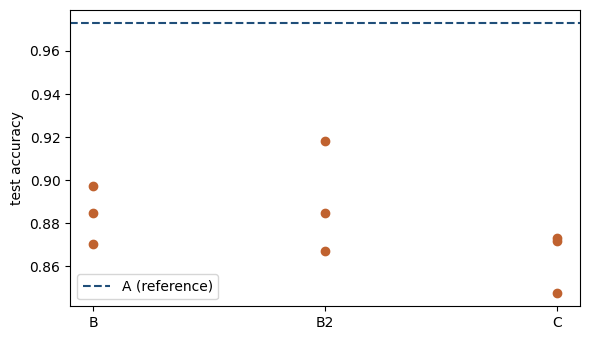

In [ ]:
RUN_SEED_REPEATS = True
SEEDS = [11, 22, 33]
SEED_CONFIGS = {"B": dict(use_clahe=False, use_weights=True),
                "B2": dict(use_clahe=False, use_weights=False),
                "C": dict(use_clahe=True, use_weights=True)}

def quick_metrics(probs, ys):
    pred = (probs >= 0.5).astype(int)
    tp = int(((pred == 1) & (ys == 1)).sum()); tn = int(((pred == 0) & (ys == 0)).sum())
    fp = int(((pred == 1) & (ys == 0)).sum()); fn = int(((pred == 0) & (ys == 1)).sum())
    return dict(accuracy=(tp + tn) / len(ys), sensitivity=tp / max(tp + fn, 1), specificity=tn / max(tn + fp, 1),
                auc=float(roc_auc_score(ys, probs)), FN=fn, FP=fp)

seed_rows = []
if RUN_SEED_REPEATS:
    for tag, kw in SEED_CONFIGS.items():
        for s in SEEDS:
            model_s, hist_s = finetune(use_clahe=kw["use_clahe"], tag=f"{tag}-seed{s}", use_weights=kw["use_weights"], seed=s)
            probs_s, ys_s = get_probs(model_s, test_clahe if kw["use_clahe"] else test_raw, [identity])
            r = dict(config=tag, seed=s, best_val_loss=min(hist_s["val_loss"]), best_epoch=int(np.argmin(hist_s["val_loss"]) + 1),
                     val_acc_at_best=hist_s["val_acc"][int(np.argmin(hist_s["val_loss"]))], **quick_metrics(probs_s, ys_s))
            seed_rows.append(r); print(r)
            pd.DataFrame(seed_rows).to_csv(f"{RESULTS_DIR}/seed_repeats.csv", index=False)
            del model_s; cleanup()
    seed_df = pd.DataFrame(seed_rows)
    summ = seed_df.groupby("config")[["accuracy", "sensitivity", "specificity", "auc", "FN", "FP"]].agg(["mean", "std"]).round(4)
    display(summ); summ.to_csv(f"{RESULTS_DIR}/seed_repeats_summary.csv")
    main_run = {k: PRED[k]["probs"] for k in ["B", "B2", "C"]}
    print("Main-run accuracy (Section 8-9):", {k: round(float(((p >= 0.5).astype(int) == ref_ys).mean()), 4) for k, p in main_run.items()})
    print("Reference checkpoint A accuracy:", round(float(((PRED['A']['probs'] >= 0.5).astype(int) == ref_ys).mean()), 4))
    plt.figure(figsize=(6, 3.5))
    for i, tag in enumerate(SEED_CONFIGS):
        v = seed_df[seed_df.config == tag].accuracy.values; plt.plot([i] * len(v), v, "o", color="#c0622f")
    plt.axhline(((PRED['A']['probs'] >= 0.5).astype(int) == ref_ys).mean(), color="#1f4e79", ls="--", label="A (reference)")
    plt.xticks(range(len(SEED_CONFIGS)), list(SEED_CONFIGS)); plt.ylabel("test accuracy"); plt.legend(); plt.tight_layout(); plt.show()
else:
    print("Seed repeats skipped.")

## 21. Optional: patient-disjoint training / validation split
Draws the training / validation split from the Kaggle train folder with `GroupShuffleSplit` so that no patient proxy is shared between training and validation (the proxy is meaningful within this folder). Experiment B (class-weighted, raw images) is repeated on this split, giving a validation set that no longer contains images of the training patients. Files whose names are not recognised are treated as separate groups. Set `RUN_GROUPED_SPLIT = True` to run it (about 5 minutes).

In [ ]:
RUN_GROUPED_SPLIT = True
if RUN_GROUPED_SPLIT:
    from sklearn.model_selection import GroupShuffleSplit
    groups = [patient_proxy(p) or p for p, _ in train_all]
    gss = GroupShuffleSplit(n_splits=1, test_size=782 / len(train_all), random_state=SEED)
    tr_idx, va_idx = next(gss.split([p for p, _ in train_all], [l for _, l in train_all], groups))
    g_tr = [train_all[i] for i in tr_idx]; g_va = [train_all[i] for i in va_idx]
    data = ([p for p, _ in g_tr], [ds2model[l] for _, l in g_tr], [p for p, _ in g_va], [ds2model[l] for _, l in g_va])
    shared_g = patient_sets(data[0]) & patient_sets(data[2])
    print("Grouped split sizes: train", len(data[0]), "val", len(data[2]), "| shared patient proxies:", len(shared_g))
    model_g, hist_g = finetune(use_clahe=False, tag="B-grouped", use_weights=True, seed=SEED, data=data)
    probs_g, ys_g = get_probs(model_g, test_raw, [identity])
    grouped = quick_metrics(probs_g, ys_g); grouped["val_acc_at_best"] = hist_g["val_acc"][int(np.argmin(hist_g["val_loss"]))]
    print("B on patient-disjoint train/val split:", grouped)
    json.dump(grouped, open(f"{RESULTS_DIR}/grouped_split_B.json", "w"), indent=2)
    del model_g; cleanup()
else:
    print("Grouped-split experiment skipped (set RUN_GROUPED_SPLIT = True to run it).")

Grouped split sizes: train 4417 val 799 | shared patient proxies: 0


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[B-grouped] class weights (model id order): [1.9789 0.669 ]
[B-grouped] epoch 1/5 | train_loss 0.0703 | val_loss 0.0608 | val_acc 0.9850 | 65s
[B-grouped] epoch 2/5 | train_loss 0.0576 | val_loss 0.0307 | val_acc 0.9925 | 65s
[B-grouped] epoch 3/5 | train_loss 0.0397 | val_loss 0.0418 | val_acc 0.9925 | 65s
[B-grouped] epoch 4/5 | train_loss 0.0134 | val_loss 0.0444 | val_acc 0.9925 | 64s
[B-grouped] early stopping at epoch 4
B on patient-disjoint train/val split: {'accuracy': 0.9102564102564102, 'sensitivity': 0.9974358974358974, 'specificity': 0.7649572649572649, 'auc': 0.9923131711593249, 'FN': 1, 'FP': 55, 'val_acc_at_best': 0.9924906132665833}


## 22. Export everything
Writes a README for the result files and zips them. Regenerate every table in the report from these files.

In [ ]:
import shutil
json.dump(HIST, open(f"{RESULTS_DIR}/finetune_histories.json", "w"), indent=2)
with open(f"{RESULTS_DIR}/README_results.txt", "w") as f:
    f.write(f"Files written by this notebook run (RUN_ID {RUN_ID})\n"
            "vit_results.csv/json      metrics at threshold 0.5 for experiments A-F (Section 10)\n"
            "predictions_test.csv      per-image probabilities and predictions (Section 14)\n"
            "metrics_with_ci.csv       accuracy/sensitivity/specificity/precision/AUC with 95% CIs, Brier, ECE\n"
            "paired_tests.csv          McNemar, paired bootstrap, Holm correction (Section 16)\n"
            "threshold_analysis.csv, prior_shift_calibration.csv   validation-chosen operating points (Section 17)\n"
            "fusion_weight_sweep.csv   fusion analysis (Section 18)\n"
            "patient_overlap.csv, overlap_audit_hf.csv, overlap_audit_summary.json   audits (Section 19)\n"
            "seed_repeats.csv, seed_repeats_summary.csv   repeated seeds (Section 20)\n"
            "split_manifest.csv, run_manifest.json   reproducibility record (Section 12)\n")
print("RUN_ID:", RUN_ID)
shutil.make_archive(f"/content/vit_results_bundle_{RUN_ID}", "zip", RESULTS_DIR)
print(sorted(os.listdir(RESULTS_DIR)))
try:
    from google.colab import files
    files.download(f"/content/vit_results_bundle_{RUN_ID}.zip")
except Exception as e:
    print("Skip download:", e)

RUN_ID: 20261030-020252
['README_results.txt', 'accuracy_by_hf_overlap.csv', 'finetune_histories.json', 'fisher_overlap.csv', 'fusion_weight_sweep.csv', 'grouped_split_B.json', 'hf_match_test.csv', 'metrics_with_ci.csv', 'overlap_audit_hf.csv', 'overlap_audit_summary.json', 'paired_tests.csv', 'patient_overlap.csv', 'predictions_test.csv', 'predictive_values.csv', 'prior_shift_calibration.csv', 'run_manifest.json', 'seed_repeats.csv', 'seed_repeats_summary.csv', 'split_manifest.csv', 'threshold_analysis.csv', 'vit_results.csv', 'vit_results.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>